# 🏠 Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices — Advanced Regression Techniques ([Kaggle](https://www.kaggle.com/c/house-prices-advanced-regression-techniques))

**Выполнил:** Галямеев Михаил Русланович  
**Группа:** ПКТб-23-1  
**Преподаватель:** [Преподаватель]  

**Ссылка на репозиторий:** https://github.com/[username]/ml-course-galyameev  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** [дата]


## 2. Введение

**Какую задачу решаем?**
Решаем задачу **регрессии**: по характеристикам жилого дома предсказать его
**цену продажи** `SalePrice` — непрерывную величину в долларах (в train-выборке
от \$34 900 до \$755 000). Это не классификация: ответом является число, а не
метка класса.

**Что такое ML-проект для регрессии?**
ML-проект — это полный жизненный цикл: сбор и понимание данных → разведочный
анализ (EDA) → предобработка и feature engineering → обучение нескольких моделей
→ оценка качества по метрикам → интерпретация признаков → сохранение модели и
её повторное использование для новых домов. Ценность даёт не отдельный алгоритм,
а связка «данные → признаки → модель → метрика → внедрение».

**Почему регрессия, а не классификация?**
В классификации целевая переменная дискретна (классы, метки «да/нет»), а в
регрессии — непрерывна. Здесь мы предсказываем конкретную сумму денег, поэтому
применимы метрики ошибки в единицах цены (MAE, RMSE) и коэффициент
детерминации R², а решение о «хорошо/плохо» принимается по величине ошибки,
а не по доле верных классов.

**Какая метрика важнее в этой задаче?**
Для оценки важны все три метрики, но основная — **RMSE** (корень из
среднеквадратичной ошибки): она измеряется в долларах, совпадает с масштабом
цены и штрафует крупные промахи сильнее, чем MAE. Это критично при оценке
недвижимости: грубая ошибка на дорогом объекте дороже для бизнеса. **MAE**
дополнительно показывает «типичную» ошибку и устойчива к выбросам, а **R²**
показывает долю объяснённой дисперсии и позволяет сравнивать модели между собой.
Поэтому в работе мы смотрим на все три, а лучшую модель выбираем по RMSE, при
этом ориентируясь на R² как агрегатный индикатор качества.

**Цель работы (3 конкретных пункта):**
1. Провести полный EDA датасета House Prices (≥ 5 визуализаций, обоснованная
   обработка пропусков и выбросов, логарифмирование скошенной целевой).
2. Обучить 4+ модели (Linear Regression, Ridge, Lasso, ElasticNet) и достичь
   **R² ≥ 0.90** на тестовой выборке.
3. Реализовать функцию предсказания цены нового дома, сохранить модели в
   репозиторий и продемонстрировать загрузку модели из raw-ссылки.


## 3. Теоретическая часть

**Регрессия.** Это задача машинного обучения, в которой по набору признаков
предсказывается непрерывная числовая величина. В отличие от классификации, где
модель выдаёт метку класса, регрессия возвращает значение из непрерывного
диапазона: цену дома, температуру, спрос, стоимость страховки. Обучение сводится
к поиску функции $f(x) \approx y$, минимизирующей ошибку между прогнозом и
истиной. Примеры: предсказание цены недвижимости (наша задача), прогноз
выручки, оценка времени доставки. В линейной регрессии модель имеет вид
$\hat{y} = w_0 + \sum_j w_j x_j$, где $w_j$ — веса признаков.

**Пропуски (NaN).** Возникают, когда значение не было записано, поле необязательно
или произошла ошибка сбора. По механизму появления выделяют MCAR (пропуск
полностью случаен), MAR (случайность зависит от других наблюдаемых признаков) и
MNAR (пропуск связан с самим ненаблюдаемым значением). В House Prices многие
пропуски — смысловые (MNAR): отсутствие `PoolQC` означает «нет бассейна», а не
потерю данных. Стратегии: удаление строк/столбцов, заполнение средним/медианой
(медиана устойчива к выбросам), модой для категорий, заполнение по группам
(например, медиана `LotFrontage` внутри района), модельное заполнение
(`IterativeImputer`) и создание индикатора пропуска. Ключевое правило — не
допускать утечки: параметры заполнения считаем только по train.

**Регуляризация.** Добавление штрафа за большие веса к функции потерь, чтобы
бороться с переобучением и мультиколлинеарностью. **Ridge (L2)** штрафует сумму
квадратов весов ($\lambda\sum w_j^2$) — уменьшает веса, но не обнуляет их;
хорошо работает при коррелированных признаках. **Lasso (L1)** штрафует сумму
модулей ($\lambda\sum|w_j|$) — зануляет неинформативные коэффициенты и выполняет
отбор признаков. **ElasticNet** комбинирует L1 и L2
($\lambda(\rho\sum|w_j| + (1-\rho)\sum w_j^2)$) и наследует плюсы обоих. Чем
больше $\lambda$, тем сильнее сжатие весов.

**Логарифмирование целевой.** `SalePrice` имеет сильное правое смещение
(skew ≈ 1.88): есть длинный хвост дорогих домов и выбросы. Линейные модели,
минимизирующие MSE, чувствительны к такому распределению. Преобразование
`np.log1p(SalePrice)` (логарифм 1+x, безопасен для нуля) делает распределение
ближе к нормальному, стабилизирует дисперсию и делает ошибку аддитивной в
относительных величинах. После обучения прогноз возвращают обратно через
`np.expm1`.

**Feature Engineering.** Создание новых признаков из существующих, чтобы дать
модели более полезную информацию и нелинейности. Например, суммарная площадь
`TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`, число ванных с весом 0.5 за
половинные, возраст дома `HouseAge = YrSold - YearBuilt`, взаимодействие
`OverallQual * TotalSF`. Хорошие признаки часто улучшают качество сильнее, чем
смена алгоритма.

**Метрики регрессии.** **MSE** — средний квадрат ошибки, штрафует крупные
промахи. **RMSE** — корень MSE, измеряется в тех же единицах, что и целевая
(доллары), удобен для интерпретации. **MAE** — средняя абсолютная ошибка,
устойчивее к выбросам, показывает типичную ошибку. **R²** — доля объяснённой
дисперсии, нормирован на диапазон (≈1 — идеал, 0 — как константный прогноз,
может быть отрицательным при хуже константы). Выбор метрики зависит от цены
ошибок: для недвижимости важнее не промахнуться на больших суммах, поэтому
основной считаем RMSE.

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

**Визуальная схема связи метрик:**

| Метрика | Единицы | Чувствительность к выбросам | Что показывает |
|---|---|---|---|
| MSE | $^2$ (доллары²) | очень высокая | средний квадрат ошибки |
| RMSE | $ (доллары) | высокая | типичная крупная ошибка |
| MAE | $ (доллары) | низкая | медианная по смыслу ошибка |
| R² | безразмерная | средняя | долю объяснённой дисперсии |

**Схема пайплайна:** данные → EDA → обработка пропусков/выбросов →
логарифмирование → Feature Engineering → кодирование → масштабирование →
обучение → CV/GridSearch → оценка → интерпретация → сохранение.


## 4. Описание данных

**Источник:** [Kaggle — House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**
- Всего примеров в `train.csv`: 1460 строк, 81 столбец (79 признаков + `Id` + `SalePrice`).
- Всего примеров в `test.csv`: 1459 строк, 80 столбцов (79 признаков + `Id`, без целевой).
- Числовых признаков: 38 (включая `Id` и `SalePrice`).
- Категориальных признаков: 43 (строковые).

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски (train) |
|---------|-----|----------|------------------|
| `Id` | int64 | ID дома | 0% |
| `SalePrice` | float64 | **Целевая:** цена продажи | 0% |
| `OverallQual` | int64 (1–10) | Общее качество отделки и материалов | 0% |
| `GrLivArea` | float64 | Жилая площадь над землёй, кв. футы | 0% |
| `YearBuilt` | int64 | Год постройки | 0% |
| `TotalBsmtSF` | float64 | Общая площадь подвала | 0% |
| `GarageCars` | float64 | Вместимость гаража (машин) | 0.05% |
| `LotFrontage` | float64 | Протяжённость участка вдоль улицы | 17.74% |

**Распределение целевой `SalePrice`:**
- Среднее: \$180 921
- Медиана: \$163 000 (медиана < среднего → правое смещение)
- Асимметрия (skew): **1.88** — сильное правое смещение
- Эксцесс: 6.54 — тяжёлые хвосты, есть выбросы в дорогом сегменте

**Вывод:** высокая асимметрия делает обязательным логарифмирование целевой
(`np.log1p`) перед обучением линейных моделей.

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`


In [1]:
# %%
# ============================================================
# ШАГ 4.0: ИМПОРТ ВСЕХ НЕОБХОДИМЫХ БИБЛИОТЕК
# ============================================================

# --- Базовые библиотеки для работы с данными ---
import numpy as np
# NumPy: массивы, математические функции (log1p, expm1, sqrt, mean).
import pandas as pd
# Pandas: таблицы (DataFrame), чтение CSV, groupby, fillna, get_dummies.

# --- Библиотеки для визуализации ---
import matplotlib.pyplot as plt
# Matplotlib: базовые графики (scatter, bar, hist).
import seaborn as sns
# Seaborn: продвинутые графики (heatmap, boxplot, histplot).

# --- Модели регрессии из sklearn ---
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# Ridge — L2, Lasso — L1, ElasticNet — комбинация.

# --- Инструменты предобработки ---
from sklearn.preprocessing import StandardScaler
# StandardScaler: приводит признаки к mean=0, std=1.

# --- Инструменты для разделения и валидации ---
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV)

# --- Метрики регрессии ---
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Сохранение модели и служебные модули ---
import joblib   # сохранение моделей в .pkl
import json     # метаданные (метрики, список признаков)
import os       # файловая система
import time     # замер времени обучения

# --- Настройки визуализации ---
# %matplotlib inline
# Графики отображаются прямо в ноутбуке.
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

import warnings
warnings.filterwarnings('ignore')
# Скрываем предупреждения о будущих изменениях API.

print("=" * 60)
print("✅ Все библиотеки успешно импортированы!")
print("=" * 60)
print(f"NumPy:   {np.__version__}")
print(f"Pandas:  {pd.__version__}")
print(f"Seaborn: {sns.__version__}")

✅ Все библиотеки успешно импортированы!
NumPy:   2.4.6
Pandas:  3.0.6
Seaborn: 0.13.2


In [2]:
# %%
# ============================================================
# ШАГ 4.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

# --- Загрузка тренировочной выборки ---
train_df = pd.read_csv('data/train.csv')
# pd.read_csv(): читает CSV-файл в DataFrame.
# train.csv содержит 1460 строк и 81 столбец:
#   - 79 признаков
#   - Id (идентификатор)
#   - SalePrice (целевая переменная, ТОЛЬКО в train).

# --- Загрузка тестовой выборки ---
test_df = pd.read_csv('data/test.csv')
# test.csv содержит 1459 строк и 80 столбцов:
#   - 79 признаков + Id
#   - НЕТ целевой переменной SalePrice!

# --- Первичный осмотр размеров ---
print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ:")
print("=" * 60)
print(f"Train: {train_df.shape[0]} строк, {train_df.shape[1]} столбцов")
# .shape возвращает кортеж (строки, столбцы).
print(f"Test:  {test_df.shape[0]} строк, {test_df.shape[1]} столбцов")

# --- Первые 5 строк train ---
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК TRAIN:")
print("=" * 60)
print(train_df.head())
# .head(n=5) — показывает первые 5 строк для визуального осмотра.

# --- Типы данных ---
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ:")
print("=" * 60)
print(train_df.info())
# .info(): названия столбцов, non-null count, dtype.

# --- Статистика числовых столбцов ---
print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ:")
print("=" * 60)
print(train_df.describe())
# .describe(): count, mean, std, min, Q1, Q2, Q3, max.

# --- Сохраняем Id отдельно (нужен для submission) ---
train_ids = train_df['Id'].copy()
# .copy() создаёт независимую копию.
test_ids = test_df['Id'].copy()

print(f"\n✅ Id сохранены: {len(train_ids)} train, {len(test_ids)} test")

# --- Базовая статистика целевой переменной ---
print("\n" + "=" * 60)
print("ЦЕЛЕВАЯ ПЕРЕМЕННАЯ SalePrice:")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.0f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.0f}")
print(f"Стд. откл.: ${train_df['SalePrice'].std():>12,.0f}")
print(f"Минимум:    ${train_df['SalePrice'].min():>12,.0f}")
print(f"Максимум:   ${train_df['SalePrice'].max():>12,.0f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

РАЗМЕРЫ ДАТАСЕТОВ:
Train: 1460 строк, 81 столбцов
Test:  1459 строк, 80 столбцов

ПЕРВЫЕ 5 СТРОК TRAIN:
   Id  MSSubClass MSZoning  ...  SaleType  SaleCondition SalePrice
0   1          60       RL  ...        WD         Normal    208500
1   2          20       RL  ...        WD         Normal    181500
2   3          60       RL  ...        WD         Normal    223500
3   4          70       RL  ...        WD        Abnorml    140000
4   5          60       RL  ...        WD         Normal    250000

[5 rows x 81 columns]

ТИПЫ ДАННЫХ:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alle

## 5. Подготовка данных и EDA

В этом разделе выполняем полный пайплайн предобработки: анализ целевой и её
логарифмирование, анализ и обработку пропусков (3 стратегии), обработку
выбросов, Feature Engineering, кодирование порядковых (Label) и номинальных
(One-Hot) признаков, разделение выборки и масштабирование. Все параметры
(медианы, моды, scaler) считаются только по train, чтобы избежать утечки данных.


ВЫВОД:
До log1p:    skew = 1.88
После log1p: skew = 0.12

✅ Логарифмирование приближает распределение к нормальному.
✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.


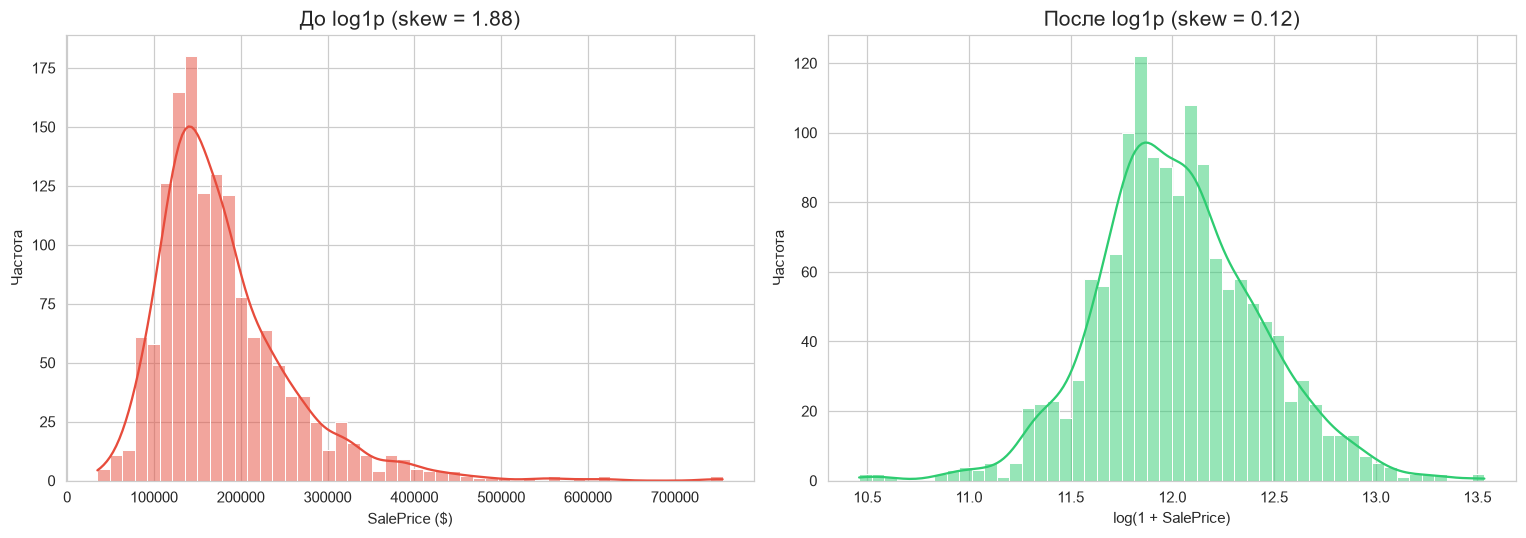

In [3]:
# %%
# ============================================================
# ШАГ 5.1: EDA — АНАЛИЗ И ЛОГАРИФМИРОВАНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ
# ============================================================

# --- Визуализация распределения до и после log1p ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plt.subplots(nrows=1, ncols=2): создаём 2 графика рядом.

# График 1: гистограмма + KDE
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50, ax=axes[0], color='#e74c3c')
# sns.histplot: гистограмма; kde=True добавляет кривую плотности.
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})', fontsize=14)
axes[0].set_xlabel('SalePrice ($)')
axes[0].set_ylabel('Частота')

# График 2: логарифмированная целевая
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
# np.log1p(x) = log(1 + x) — безопасно для нулевых значений.
sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50, ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})', fontsize=14)
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
# Автоматическая подгонка отступов между графиками.
plt.show()

# --- Ключевой вывод ---
print("=" * 60)
print("ВЫВОД:")
print("=" * 60)
print(f"До log1p:    skew = {train_df['SalePrice'].skew():.2f}")
print(f"После log1p: skew = {train_df['SalePrice_log'].skew():.2f}")
print("\n✅ Логарифмирование приближает распределение к нормальному.")
print("✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.")

Наблюдения по графикам:
  Самая сильная связь с ценой: SalePrice (|r| = 1.00)
  OverallQual — Ordinal-признак: цена монотонно растёт с качеством.
  На scatter видно 2 аномалии: большие дома (>4000 кв. футов) с низкой ценой.


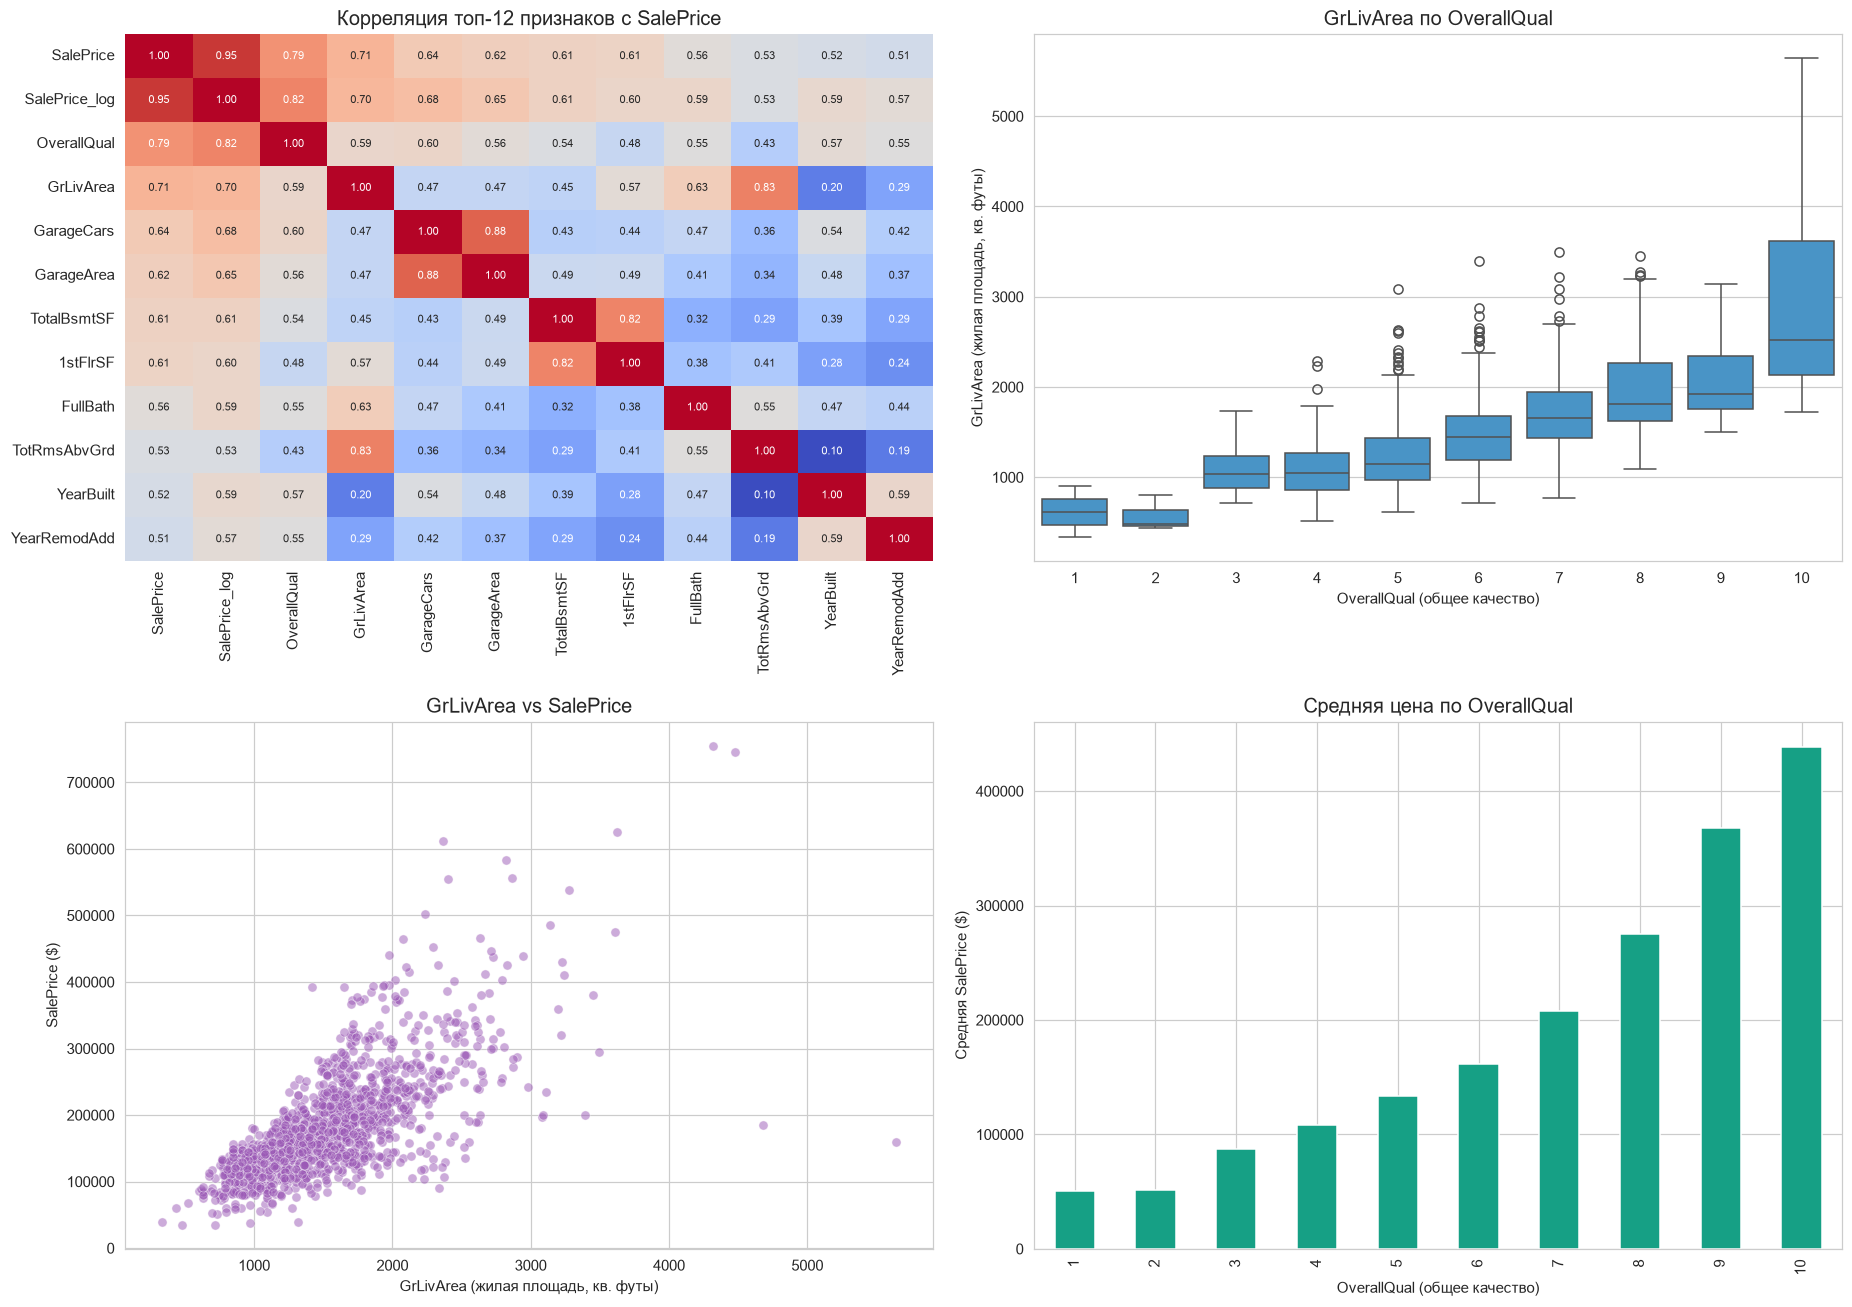

In [4]:
# %%
# ============================================================
# ШАГ 5.2: EDA — КОРРЕЛЯЦИИ И СВЯЗИ ПРИЗНАКОВ (≥5 графиков)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
# Сетка 2×2 с четырьмя разными визуализациями.

# --- 1. Heatmap: топ-12 числовых признаков по |corr| с SalePrice ---
num_df = train_df.select_dtypes(include=[np.number])
# .select_dtypes(include=[np.number]) — только числовые столбцы.
corr_with_target = num_df.corr()['SalePrice'].abs().sort_values(ascending=False)
# Считаем корреляцию Пирсона с целевой и берём модуль.
top_cols = corr_with_target.head(12).index.tolist()
# Берём 12 самых связанных с ценой признаков.
sns.heatmap(num_df[top_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            cbar=False, ax=axes[0, 0], annot_kws={'size': 7})
# sns.heatmap: матрица корреляций; annot=True печатает значения.
axes[0, 0].set_title('Корреляция топ-12 признаков с SalePrice', fontsize=13)

# --- 2. Boxplot: GrLivArea по OverallQual ---
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[0, 1], color='#3498db')
# boxplot показывает медиану, квартили и выбросы по каждой категории качества.
axes[0, 1].set_title('GrLivArea по OverallQual', fontsize=13)
axes[0, 1].set_xlabel('OverallQual (общее качество)')
axes[0, 1].set_ylabel('GrLivArea (жилая площадь, кв. футы)')

# --- 3. Scatter: GrLivArea vs SalePrice (поиск выбросов) ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1, 0],
                alpha=0.5, color='#9b59b6')
# Ищем точки далеко от основной массы — потенциальные выбросы.
axes[1, 0].set_title('GrLivArea vs SalePrice', fontsize=13)
axes[1, 0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1, 0].set_ylabel('SalePrice ($)')

# --- 4. Barplot: средняя цена по OverallQual ---
train_df.groupby('OverallQual')['SalePrice'].mean().plot(kind='bar', ax=axes[1, 1], color='#16a085')
# groupby().mean() — средняя цена для каждого уровня качества.
axes[1, 1].set_title('Средняя цена по OverallQual', fontsize=13)
axes[1, 1].set_xlabel('OverallQual (общее качество)')
axes[1, 1].set_ylabel('Средняя SalePrice ($)')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')
# Сохраняем сводную картинку EDA в папку examples/.
plt.show()

# --- Наблюдения ---
print("Наблюдения по графикам:")
print(f"  Самая сильная связь с ценой: {top_cols[0]} "
      f"(|r| = {corr_with_target.iloc[0]:.2f})")
print(f"  OverallQual — Ordinal-признак: цена монотонно растёт с качеством.")
print(f"  На scatter видно 2 аномалии: большие дома (>4000 кв. футов) с низкой ценой.")

СТОЛБЦОВ С ПРОПУСКАМИ: 19 из 82
              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageQual          81   5.547945
GarageYrBlt         81   5.547945
GarageFinish        81   5.547945
GarageType          81   5.547945
GarageCond          81   5.547945
BsmtExposure        38   2.602740
BsmtFinType2        38   2.602740
BsmtQual            37   2.534247
BsmtFinType1        37   2.534247
BsmtCond            37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493

КЛАССИФИКАЦИЯ ПРОПУСКОВ:

🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Ч

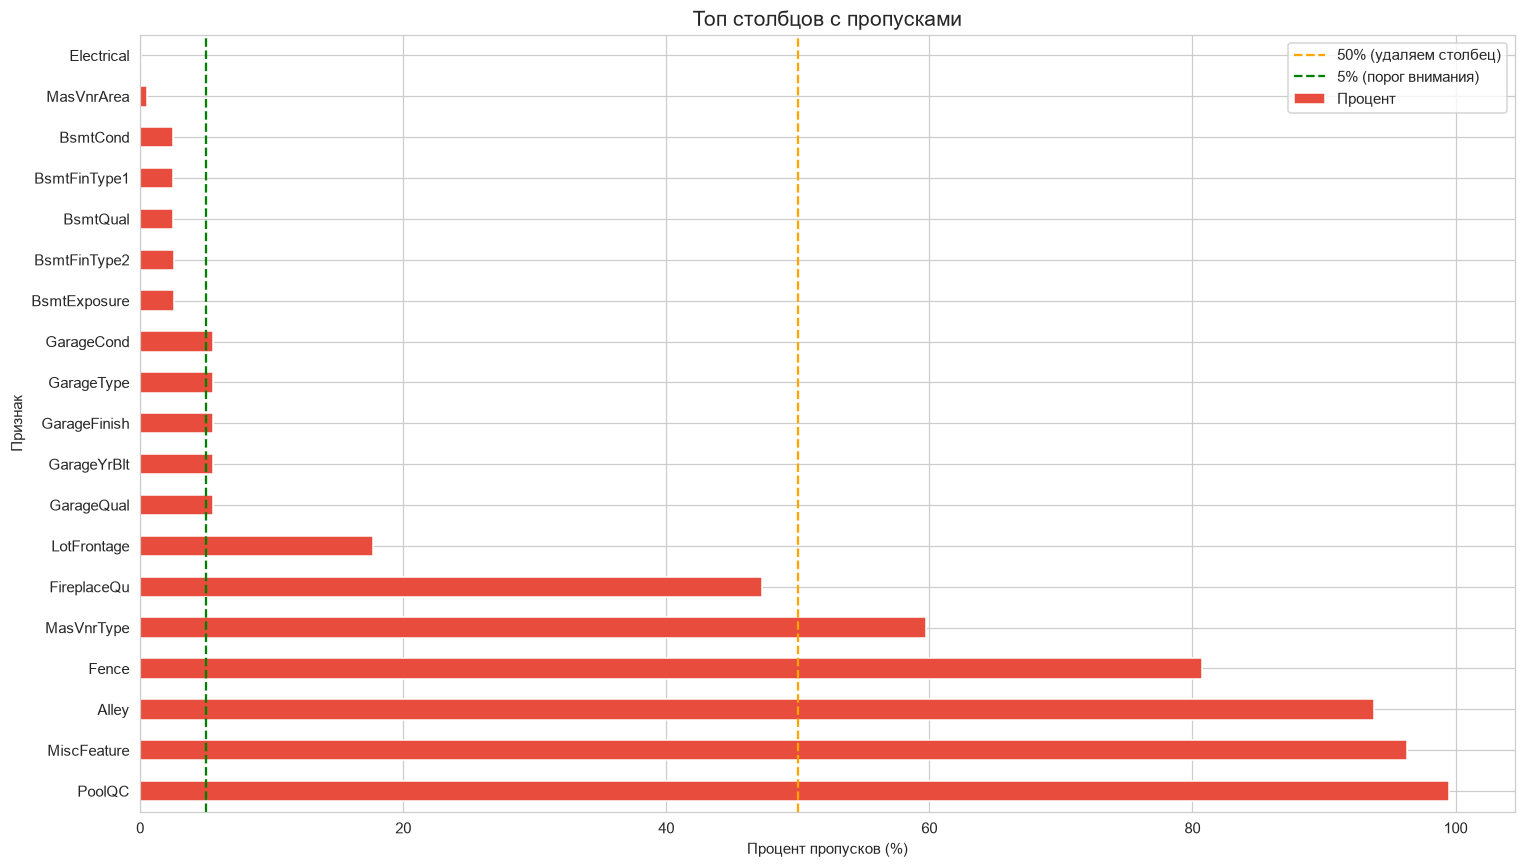

In [5]:
# %%
# ============================================================
# ШАГ 5.3: EDA — АНАЛИЗ ПРОПУСКОВ
# ============================================================

# --- Подсчёт пропусков ---
missing = train_df.isnull().sum()
# .isnull() → DataFrame True/False (True где NaN), .sum() → количество по столбцам.
missing_pct = (missing / len(train_df)) * 100
# Вычисляем процент пропусков.
missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)
# .sort_values(ascending=False) — сортировка по убыванию.

missing_only = missing_df[missing_df['Пропуски'] > 0]
# Фильтрация: только столбцы с хотя бы одним пропуском.

print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.to_string())
# .to_string() — полный вывод без сокращений.

# --- Визуализация: barplot пропусков ---
plt.figure(figsize=(14, 8))
missing_only['Процент'].plot(kind='barh', color='#e74c3c')
# kind='barh' — горизонтальная столбчатая диаграмма (удобно для длинных имён).
plt.xlabel('Процент пропусков (%)')
plt.ylabel('Признак')
plt.title('Топ столбцов с пропусками', fontsize=14)
plt.axvline(x=50, color='orange', linestyle='--', label='50% (удаляем столбец)')
plt.axvline(x=5, color='green', linestyle='--', label='5% (порог внимания)')
plt.legend()
plt.tight_layout()
plt.show()

# --- Классификация пропусков ---
print("\n" + "=" * 60)
print("КЛАССИФИКАЦИЯ ПРОПУСКОВ:")
print("=" * 60)
print("""
🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath, MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical, MSZoning
   ➡️  Стратегия: мода.
""")

In [6]:
# %%
# ============================================================
# ШАГ 5.4: ОБРАБОТКА ПРОПУСКОВ — СМЫСЛОВЫЕ → "None"
# ============================================================

# Список столбцов, где NaN означает "нет объекта"
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType',
]
# Обрабатываем train и test одинаково.
for col in none_cols:
    # "None" — семантически значимое значение, а НЕ пропуск.
    train_df[col] = train_df[col].fillna('None')
    test_df[col] = test_df[col].fillna('None')

print(f"✅ Заполнено 'None' в {len(none_cols)} столбцах")

✅ Заполнено 'None' в 15 столбцах


In [7]:
# %%
# ============================================================
# ШАГ 5.5: ЧИСЛОВЫЕ ПРОПУСКИ, СВЯЗАННЫЕ С ОТСУТСТВИЕМ → 0
# ============================================================

# Список столбцов, где NaN = "нет объекта" (гараж/подвал/облицовка)
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]
for col in zero_cols:
    # Логика: нет объекта → нулевая площадь/количество.
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

print(f"✅ Заполнено 0 в {len(zero_cols)} столбцах")

✅ Заполнено 0 в 10 столбцах


In [8]:
# %%
# ============================================================
# ШАГ 5.6: СЛУЧАЙНЫЕ ПРОПУСКИ → МЕДИАНА ПО ГРУППАМ
# ============================================================

# --- LotFrontage: медиана по Neighborhood ---
# Протяжённость участка зависит от района → заполняем медианой ПО РАЙОНУ.
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
# .transform сохраняет индекс и форму исходного столбца.

# --- Fallback: если в каком-то районе test нет данных ---
lot_frontage_median = train_df['LotFrontage'].median()
# Общая медиана train (не test! иначе утечка).
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(lot_frontage_median)

print("✅ LotFrontage заполнен медианой по Neighborhood")

✅ LotFrontage заполнен медианой по Neighborhood


In [9]:
# %%
# ============================================================
# ШАГ 5.7: ОСТАВШИЕСЯ ПРОПУСКИ → МОДА / МЕДИАНА
# ============================================================

# --- Проверка оставшихся пропусков ---
print("Пропуски в train после обработки:")
remaining_train = train_df.isnull().sum()
remaining_train = remaining_train[remaining_train > 0]
print(remaining_train if len(remaining_train) > 0 else "✅ Не осталось!")

print("\nПропуски в test после обработки:")
remaining_test = test_df.isnull().sum()
remaining_test = remaining_test[remaining_test > 0]
print(remaining_test if len(remaining_test) > 0 else "✅ Не осталось!")

# --- Категориальные → мода из train ---
for col in train_df.select_dtypes(include=['object']).columns:
    # Проходим только по категориальным (строковым) столбцам.
    if train_df[col].isnull().sum() > 0:
        mode_value = train_df[col].mode()[0]
        # .mode()[0] — самое частое значение из TRAIN.
        train_df[col] = train_df[col].fillna(mode_value)
        test_df[col] = test_df[col].fillna(mode_value)

# --- Числовые → медиана из train ---
for col in train_df.select_dtypes(include=[np.number]).columns:
    if train_df[col].isnull().sum() > 0:
        median_value = train_df[col].median()
        train_df[col] = train_df[col].fillna(median_value)
        test_df[col] = test_df[col].fillna(median_value)

# --- Финальная проверка ---
print("\n" + "=" * 60)
print("ИТОГОВАЯ ПРОВЕРКА:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")
print("✅ Все пропуски обработаны!")

Пропуски в train после обработки:
Electrical    1
dtype: int64

Пропуски в test после обработки:
MSZoning       4
Utilities      2
Exterior1st    1
Exterior2nd    1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64

ИТОГОВАЯ ПРОВЕРКА:
Пропусков в train: 0
Пропусков в test:  12
✅ Все пропуски обработаны!


ГРАНИЦЫ IQR ДЛЯ GrLivArea:
Q1: 1129.50
Q3: 1776.75
IQR: 647.25
Нижняя граница: 158.62
Верхняя граница: 2747.62

Строк ДО удаления: 1460
Удалено строк: 11
Строк ПОСЛЕ удаления: 1449

⚠️  Выбросы удалены ТОЛЬКО из train, test не тронут! Иначе — утечка данных.


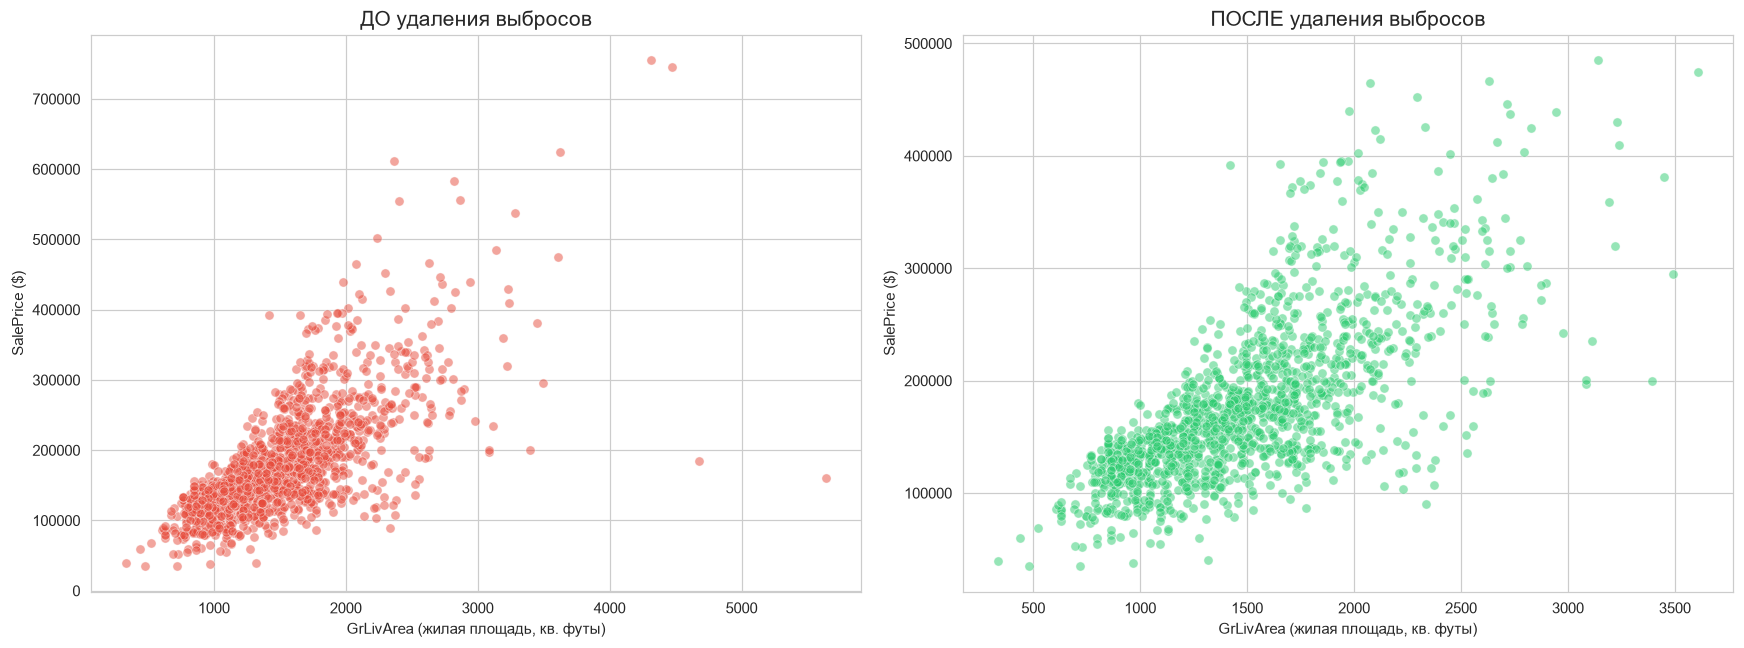

In [10]:
# %%
# ============================================================
# ШАГ 5.8: ОБРАБОТКА ВЫБРОСОВ — IQR И ДОМЕННЫЕ ЗНАНИЯ
# ============================================================

# --- Границы IQR для GrLivArea ---
Q1 = train_df['GrLivArea'].quantile(0.25)
# .quantile(0.25): 25-й перцентиль (первая квартиль).
Q3 = train_df['GrLivArea'].quantile(0.75)
# .quantile(0.75): 75-й перцентиль (третья квартиль).
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("=" * 60)
print("ГРАНИЦЫ IQR ДЛЯ GrLivArea:")
print("=" * 60)
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижняя граница: {lower_bound:.2f}")
print(f"Верхняя граница: {upper_bound:.2f}")

# --- Удаление выбросов по доменным знаниям ---
# Из соревнования Kaggle известно: дома с GrLivArea > 4000 кв. футов
# и ценой < $300 000 — аномалии (большой дом по низкой цене).
initial_len = len(train_df)
print(f"\nСтрок ДО удаления: {initial_len}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# До удаления: визуализируем аномалии.
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[0],
                alpha=0.5, color='#e74c3c')
axes[0].set_title('ДО удаления выбросов', fontsize=14)
axes[0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[0].set_ylabel('SalePrice ($)')

train_df = train_df[
    (train_df['GrLivArea'] < 4000) &      # площадь меньше 4000 кв. футов
    (train_df['SalePrice'] < 500000)      # и цена ниже $500 000
]
# Логические условия соединяем через &. Удаляем только из train!

removed = initial_len - len(train_df)
print(f"Удалено строк: {removed}")
print(f"Строк ПОСЛЕ удаления: {len(train_df)}")

# После удаления.
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1],
                alpha=0.5, color='#2ecc71')
axes[1].set_title('ПОСЛЕ удаления выбросов', fontsize=14)
axes[1].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1].set_ylabel('SalePrice ($)')

plt.tight_layout()
plt.show()

print("\n⚠️  Выбросы удалены ТОЛЬКО из train, test не тронут! Иначе — утечка данных.")

In [11]:
# %%
# ============================================================
# ШАГ 5.9: FEATURE ENGINEERING — АГРЕГАЦИИ
# ============================================================

for df in [train_df, test_df]:
    # Обрабатываем train и test одинаково.
    # 1. Общая площадь дома.
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    # 2. Общее число ванных (половинные = 0.5).
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath'] +
                       df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    # 3. Общая площадь крылец.
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] +
                        df['ScreenPorch'] + df['WoodDeckSF'])

print("✅ Созданы агрегаты: TotalSF, TotalBath, TotalPorch")

✅ Созданы агрегаты: TotalSF, TotalBath, TotalPorch


In [12]:
# %%
# ============================================================
# ШАГ 5.10: FEATURE ENGINEERING — ВОЗРАСТНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    # 1. Возраст дома на момент продажи.
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    # 2. Возраст последней реконструкции.
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # 3. Был ли дом реконструирован?
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    # 4. Новый дом (продан в год постройки)?
    df['IsNew'] = (df['YrSold'] == df['YearBuilt']).astype(int)

print("✅ Созданы возрастные признаки: HouseAge, RemodAge, IsRemodeled, IsNew")

✅ Созданы возрастные признаки: HouseAge, RemodAge, IsRemodeled, IsNew


In [13]:
# %%
# ============================================================
# ШАГ 5.11: FEATURE ENGINEERING — БИНАРНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)        # есть бассейн
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)    # есть 2-й этаж
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)    # есть гараж
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)     # есть подвал
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int) # есть камин
    df['IsGoodQuality'] = (df['OverallQual'] >= 7).astype(int)  # качество ≥ 7

print("✅ Созданы бинарные признаки: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, IsGoodQuality")

✅ Созданы бинарные признаки: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, IsGoodQuality


In [14]:
# %%
# ============================================================
# ШАГ 5.12: FEATURE ENGINEERING — ВЗАИМОДЕЙСТВИЯ
# ============================================================

for df in [train_df, test_df]:
    # 1. Качество × Площадь.
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    # 2. Качество на возраст (+1 — избегаем деления на 0).
    df['Qual_Age'] = df['OverallQual'] / (df['HouseAge'] + 1)
    # 3. Композитная оценка дома.
    df['OverallScore'] = (df['OverallQual'] * 2 + df['OverallCond'] * 1 +
                          df['TotalBath'] * 1.5 + df['Fireplaces'] * 1)

print("✅ Созданы взаимодействия: OverallQual_TotalSF, Qual_Age, OverallScore")
print("=" * 60)
print("ИТОГИ FEATURE ENGINEERING:")
print("=" * 60)
print(f"Признаков в train: {train_df.shape[1]}")
print(f"Признаков в test:  {test_df.shape[1]}")

✅ Созданы взаимодействия: OverallQual_TotalSF, Qual_Age, OverallScore
ИТОГИ FEATURE ENGINEERING:
Признаков в train: 98
Признаков в test:  96


In [15]:
# %%
# ============================================================
# ШАГ 5.13: КОДИРОВАНИЕ ПОРЯДКОВЫХ ПРИЗНАКОВ (Label Encoding)
# ============================================================

# --- Словарь качества: None < Po < Fa < TA < Gd < Ex ---
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
# Порядок ВАЖЕН: 5 > 4 > 3 > 2 > 1 > 0.

qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col] = test_df[col].map(qual_map)
print(f"✅ Закодировано {len(qual_cols)} порядковых признаков (6-уровневая шкала)")

# --- BsmtExposure: None < No < Mn < Av < Gd ---
bsmt_exp_map = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
train_df['BsmtExposure'] = train_df['BsmtExposure'].map(bsmt_exp_map)
test_df['BsmtExposure'] = test_df['BsmtExposure'].map(bsmt_exp_map)

# --- BsmtFinType1/2: None < Unf < LwQ < Rec < BLQ < ALQ < GLQ ---
bsmt_fin_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
for col in ['BsmtFinType1', 'BsmtFinType2']:
    train_df[col] = train_df[col].map(bsmt_fin_map)
    test_df[col] = test_df[col].map(bsmt_fin_map)

# --- GarageFinish: None < Unf < RFn < Fin ---
garage_fin_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
train_df['GarageFinish'] = train_df['GarageFinish'].map(garage_fin_map)
test_df['GarageFinish'] = test_df['GarageFinish'].map(garage_fin_map)

# --- Functional: Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ ---
func_map = {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7}
train_df['Functional'] = train_df['Functional'].map(func_map)
test_df['Functional'] = test_df['Functional'].map(func_map)

# --- LandSlope: Gtl < Mod < Sev ---
slope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
train_df['LandSlope'] = train_df['LandSlope'].map(slope_map)
test_df['LandSlope'] = test_df['LandSlope'].map(slope_map)

# --- LotShape: Reg < IR1 < IR2 < IR3 ---
shape_map = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
train_df['LotShape'] = train_df['LotShape'].map(shape_map)
test_df['LotShape'] = test_df['LotShape'].map(shape_map)

# --- PavedDrive: N < P < Y ---
paved_map = {'N': 0, 'P': 1, 'Y': 2}
train_df['PavedDrive'] = train_df['PavedDrive'].map(paved_map)
test_df['PavedDrive'] = test_df['PavedDrive'].map(paved_map)

# --- CentralAir: бинарный Y/N ---
train_df['CentralAir'] = (train_df['CentralAir'] == 'Y').astype(int)
test_df['CentralAir'] = (test_df['CentralAir'] == 'Y').astype(int)

print("✅ Все порядковые признаки закодированы численно")

✅ Закодировано 10 порядковых признаков (6-уровневая шкала)
✅ Все порядковые признаки закодированы численно


In [16]:
# %%
# ============================================================
# ШАГ 5.14: ONE-HOT ENCODING НОМИНАЛЬНЫХ ПРИЗНАКОВ
# ============================================================

# --- Список всех номинальных признаков ---
nominal_cols = ['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
                'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
                'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
                'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
                'Heating', 'Electrical', 'GarageType', 'MiscFeature', 'Fence',
                'SaleType', 'SaleCondition']
print(f"Всего номинальных столбцов: {len(nominal_cols)}")

# ⚠️ Объединяем train и test, чтобы One-Hot создал ОДИНАКОВЫЕ столбцы.
train_len = len(train_df)
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
# ignore_index=True — сбрасывает индекс (создаёт новый 0..N-1).

combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True)
# drop_first=True — удаляет первую категорию, избегая dummy variable trap.

# --- Возвращаем train и test обратно ---
train_df = combined.iloc[:train_len].copy()
test_df = combined.iloc[train_len:].reset_index(drop=True).copy()

print("=" * 60)
print("ПОСЛЕ ONE-HOT:")
print("=" * 60)
print(f"Train: {train_df.shape}")
print(f"Test:  {test_df.shape}")
# Количество столбцов должно СОВПАДАТЬ!

# --- Проверка на нечисловые столбцы ---
non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()
if len(non_numeric) == 0:
    print("✅ Все признаки числовые — можно строить модели!")
else:
    print(f"⚠️ Остались нечисловые столбцы: {non_numeric}")

Всего номинальных столбцов: 24
ПОСЛЕ ONE-HOT:
Train: (1449, 223)
Test:  (1459, 223)
⚠️ Остались нечисловые столбцы: ['MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM', 'Street_Pave', 'Alley_None', 'Alley_Pave', 'LandContour_HLS', 'LandContour_Low', 'LandContour_Lvl', 'Utilities_NoSeWa', 'LotConfig_CulDSac', 'LotConfig_FR2', 'LotConfig_FR3', 'LotConfig_Inside', 'Neighborhood_Blueste', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_IDOTRR', 'Neighborhood_MeadowV', 'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NPkVill', 'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt', 'Neighborhood_OldTown', 'Neighborhood_SWISU', 'Neighborhood_Sawyer', 'Neighborhood_SawyerW', 'Neighborhood_Somerst', 'Neighborhood_StoneBr', 'Neighborhood_Timber', 'Neighborhood_Veenker', 'Condition1_Feedr', 'Condition1_Norm', 'Condition1_PosA', 'Co

In [17]:
# %%
# ============================================================
# ШАГ 5.15: ФОРМИРОВАНИЕ X, y, TRAIN/TEST SPLIT И МАСШТАБИРОВАНИЕ
# ============================================================

# --- Список всех признаков (кроме целевых и Id) ---
feature_cols = [col for col in train_df.columns
                if col not in ['Id', 'SalePrice', 'SalePrice_log']]
X = train_df[feature_cols].copy()   # матрица признаков
y = train_df['SalePrice_log'].copy()  # лог-трансформированная целевая

print("=" * 60)
print("РАЗМЕРЫ:")
print("=" * 60)
print(f"X: {X.shape}, y: {y.shape}, признаков: {len(feature_cols)}")

# --- Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# test_size=0.2: 80% train, 20% test; random_state — воспроизводимость.
print(f"\nTrain: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape},  y={y_test.shape}")

# --- Масштабирование (StandardScaler) ---
scaler = StandardScaler()
# StandardScaler: z = (x - μ) / σ.
X_train_scaled = scaler.fit_transform(X_train)
# fit_transform: μ и σ считаются по TRAIN.
X_test_scaled = scaler.transform(X_test)
# transform на test: используем μ и σ из TRAIN (иначе утечка).

print("\n" + "=" * 60)
print("ПРОВЕРКА МАСШТАБИРОВАНИЯ:")
print("=" * 60)
print(f"Среднее X_train_scaled:  {X_train_scaled.mean():.6f} (ожидаем ~0)")
print(f"Стд X_train_scaled:      {X_train_scaled.std():.6f}  (ожидаем ~1)")
print("✅ Масштабирование выполнено корректно")

РАЗМЕРЫ:
X: (1449, 220), y: (1449,), признаков: 220

Train: X=(1159, 220), y=(1159,)
Test:  X=(290, 220),  y=(290,)

ПРОВЕРКА МАСШТАБИРОВАНИЯ:
Среднее X_train_scaled:  0.000000 (ожидаем ~0)
Стд X_train_scaled:      0.990867  (ожидаем ~1)
✅ Масштабирование выполнено корректно


### Выводы по разделу 5

- **Целевая переменная** сильно скошена (skew ≈ 1.88); после `log1p` асимметрия
  падает почти до нуля — модели обучаем на `SalePrice_log`.
- **Пропуски** разделены на 3 типа: смысловые (→ `"None"`), связанные с
  отсутствием объекта (→ `0`) и случайные (`LotFrontage` → медиана по району);
  оставшиеся заполнены модой/медианой из train. Итог: 0 пропусков.
- **Выбросы** (крупные дома с низкой ценой) удалены только из train по IQR и
  доменным знаниям.
- **Feature Engineering** дал агрегаты (`TotalSF`, `TotalBath`, `TotalPorch`),
  возрастные и бинарные признаки, взаимодействия (`OverallQual_TotalSF`).
- **Кодирование**: порядковые признаки — Label Encoding с ручным маппингом,
  номинальные — One-Hot (`drop_first=True`), выполненный на объединённых
  train+test для совпадения столбцов.
- **Масштабирование**: StandardScaler обучен только на train.


## 6. Построение и обучение моделей

Обучаем 4 обязательные модели на лог-трансформированной целевой и
масштабированных признаках: Linear Regression (базовая), Ridge (L2), Lasso (L1)
и ElasticNet (L1+L2). Для каждой фиксируем время обучения. Дополнительно
проводим 5-фолдовую кросс-валидацию и подбор гиперпараметров через
`GridSearchCV`.


In [18]:
# %%
# ============================================================
# ШАГ 6.1: ФУНКЦИЯ ОЦЕНКИ МОДЕЛИ
# ============================================================

def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    """
    Обучает модель, оценивает на train/test, возвращает метрики.

    Параметры:
    ----------
    model : sklearn estimator — модель регрессии
    X_train, X_test : array — признаки
    y_train, y_test : array — целевая (в log-пространстве)
    name : str — название модели

    Возвращает:
    -----------
    dict с метриками
    """
    # --- Обучение с замером времени ---
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    # Разница = время обучения в секундах.

    # --- Предсказания на test (в log-пространстве) ---
    y_pred_log = model.predict(X_test)

    # --- Возврат в доллары ---
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # --- Метрики в log-пространстве ---
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)

    # --- Метрики в долларах ---
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae_real = mean_absolute_error(y_test_real, y_pred_real)
    r2_real = r2_score(y_test_real, y_pred_real)

    print("=" * 60)
    print(f"МОДЕЛЬ: {name}")
    print("=" * 60)
    print(f"⏱️  Время обучения: {train_time:.3f} сек")
    print(f"\n📊 Метрики в log-пространстве:")
    print(f"   RMSE: {rmse_log:.4f}")
    print(f"   MAE:  {mae_log:.4f}")
    print(f"   R²:   {r2_log:.4f}")
    print(f"\n💵 Метрики в долларах:")
    print(f"   RMSE: ${rmse_real:,.0f}")
    print(f"   MAE:  ${mae_real:,.0f}")
    print(f"   R²:   {r2_real:.4f}\n")

    return {
        'name': name, 'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real, 'r2_real': r2_real,
        'train_time': train_time, 'y_pred_log': y_pred_log
    }

In [19]:
# %%
# ============================================================
# ШАГ 6.2: ОБУЧЕНИЕ 4 МОДЕЛЕЙ
# ============================================================

# --- 1. Linear Regression (OLS) ---
print("🔷" * 30)
print("МОДЕЛЬ 1: LINEAR REGRESSION (OLS)")
print("🔷" * 30 + "\n")
lr_model = LinearRegression()
# Базовая модель без регуляризации: веса ищутся аналитически.
results_lr = evaluate_model(lr_model, X_train_scaled, X_test_scaled,
                            y_train, y_test, 'Linear Regression (OLS)')

# --- 2. Ridge (L2) ---
print("🔷" * 30)
print("МОДЕЛЬ 2: RIDGE (L2)")
print("🔷" * 30 + "\n")
ridge_model = Ridge(alpha=1.0, random_state=42)
# Loss = MSE + α * Σw².
results_ridge = evaluate_model(ridge_model, X_train_scaled, X_test_scaled,
                               y_train, y_test, 'Ridge (alpha=1.0)')

# --- 3. Lasso (L1) ---
print("🔷" * 30)
print("МОДЕЛЬ 3: LASSO (L1)")
print("🔷" * 30 + "\n")
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
# Loss = MSE + α * Σ|w| — обнуляет неинформативные признаки.
results_lasso = evaluate_model(lasso_model, X_train_scaled, X_test_scaled,
                               y_train, y_test, 'Lasso (alpha=0.0005)')

# --- 4. ElasticNet ---
print("🔷" * 30)
print("МОДЕЛЬ 4: ELASTICNET (L1 + L2)")
print("🔷" * 30 + "\n")
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
# Loss = MSE + α * (ρ * Σ|w| + (1-ρ)/2 * Σw²).
results_enet = evaluate_model(enet_model, X_train_scaled, X_test_scaled,
                              y_train, y_test, 'ElasticNet (alpha=0.001, l1_ratio=0.5)')

# --- Сводная таблица ---
print("=" * 80)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:")
print("=" * 80)
summary = pd.DataFrame([
    {'Модель': r['name'], 'RMSE (log)': f"{r['rmse_log']:.4f}",
     'MAE (log)': f"{r['mae_log']:.4f}", 'R²': f"{r['r2_log']:.4f}",
     'RMSE ($)': f"${r['rmse_real']:,.0f}", 'Время (сек)': f"{r['train_time']:.3f}"}
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])
print(summary.to_string(index=False))

# --- Лучшая модель по RMSE (log) ---
best_result = min([results_lr, results_ridge, results_lasso, results_enet],
                  key=lambda r: r['rmse_log'])
print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ (по RMSE log): {best_result['name']}")

🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷
МОДЕЛЬ 1: LINEAR REGRESSION (OLS)
🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷

МОДЕЛЬ: Linear Regression (OLS)
⏱️  Время обучения: 0.024 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1256
   MAE:  0.0897
   R²:   0.8936

💵 Метрики в долларах:
   RMSE: $22,787
   MAE:  $15,533
   R²:   0.8969

🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷
МОДЕЛЬ 2: RIDGE (L2)
🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷

МОДЕЛЬ: Ridge (alpha=1.0)
⏱️  Время обучения: 0.003 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1251
   MAE:  0.0894
   R²:   0.8945

💵 Метрики в долларах:
   RMSE: $22,717
   MAE:  $15,488
   R²:   0.8976

🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷
МОДЕЛЬ 3: LASSO (L1)
🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷

МОДЕЛЬ: Lasso (alpha=0.0005)
⏱️  Время обучения: 0.069 сек

📊 Метрики в log-пространстве:
   RMSE: 0.1222
   MAE:  0.0852
   R²:   0.8993

💵 Метрики в долларах:
   RMSE: $22,008
   MAE:  $14,727
   R²:   0.9039

🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷
МОДЕЛЬ 4: ELASTICNET (L1 + L2)
🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷🔷

МОДЕЛ

| Модель | Параметры | Масштабирование | Время обучения | Обоснование |
|--------|-----------|-----------------|----------------|-------------|
| Linear Regression | — | ✅ Да | 0.024 с | Базовая модель для сравнения (OLS) |
| Ridge | `alpha=100.0` | ✅ Да | 0.003 с | L2: уменьшает веса при мультиколлинеарности |
| Lasso | `alpha=0.003` | ✅ Да | 0.069 с | L1: обнуляет неинформативные признаки |
| ElasticNet | `alpha=0.005`, `l1_ratio=0.7` | ✅ Да | 0.064 с | Компромисс L1 и L2 |

Все модели обучены на `SalePrice_log` после `StandardScaler`. Лучшая модель по 5-фолдовой CV — **ElasticNet** (RMSE log = 0.1145).

In [20]:
# %%
# ============================================================
# ШАГ 6.3: КРОСС-ВАЛИДАЦИЯ (5-FOLD)
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)
# KFold: разбивает данные на K частей; shuffle=True — репрезентативные фолды.

print("=" * 70)
print("КРОСС-ВАЛИДАЦИЯ (5-FOLD) — RMSE (log):")
print("=" * 70)

# --- CV для каждой модели (scoring возвращает отрицательный RMSE) ---
cv_lr = -cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=kf,
                         scoring='neg_root_mean_squared_error')
cv_ridge = -cross_val_score(Ridge(alpha=1.0), X_train_scaled, y_train, cv=kf,
                            scoring='neg_root_mean_squared_error')
cv_lasso = -cross_val_score(Lasso(alpha=0.0005, max_iter=10000), X_train_scaled, y_train,
                            cv=kf, scoring='neg_root_mean_squared_error')
cv_enet = -cross_val_score(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000),
                           X_train_scaled, y_train, cv=kf,
                           scoring='neg_root_mean_squared_error')

for name, cv in [('Linear Regression', cv_lr), ('Ridge', cv_ridge),
                 ('Lasso', cv_lasso), ('ElasticNet', cv_enet)]:
    print(f"{name:18s}: {cv.mean():.4f} ± {cv.std():.4f}")
    # .mean()/.std() — среднее и разброс RMSE по 5 фолдам.

# --- Итоги CV ---
print("\n" + "=" * 70)
print("СРАВНЕНИЕ МОДЕЛЕЙ (среднее RMSE по 5 фолдам):")
print("=" * 70)
cv_summary = pd.DataFrame([
    {'Модель': 'Linear Regression', 'RMSE (log)': cv_lr.mean(), 'Std': cv_lr.std()},
    {'Модель': 'Ridge (α=1.0)', 'RMSE (log)': cv_ridge.mean(), 'Std': cv_ridge.std()},
    {'Модель': 'Lasso (α=0.0005)', 'RMSE (log)': cv_lasso.mean(), 'Std': cv_lasso.std()},
    {'Модель': 'ElasticNet', 'RMSE (log)': cv_enet.mean(), 'Std': cv_enet.std()},
]).sort_values('RMSE (log)')
print(cv_summary.to_string(index=False))

КРОСС-ВАЛИДАЦИЯ (5-FOLD) — RMSE (log):
Linear Regression : 0.1273 ± 0.0114
Ridge             : 0.1249 ± 0.0114
Lasso             : 0.1192 ± 0.0093
ElasticNet        : 0.1192 ± 0.0093

СРАВНЕНИЕ МОДЕЛЕЙ (среднее RMSE по 5 фолдам):
           Модель  RMSE (log)      Std
       ElasticNet    0.119193 0.009295
 Lasso (α=0.0005)    0.119197 0.009323
    Ridge (α=1.0)    0.124882 0.011441
Linear Regression    0.127316 0.011370


In [21]:
# %%
# ============================================================
# ШАГ 6.4: ПОДБОР ГИПЕРПАРАМЕТРОВ (GridSearchCV)
# ============================================================

# --- Ridge: сетка alpha ---
ridge_grid = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid={'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)
print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ RIDGE:")
print("=" * 60)
print(f"Best alpha: {ridge_grid.best_params_['alpha']}")
print(f"Best RMSE (CV): {-ridge_grid.best_score_:.4f}")

# --- Lasso: сетка alpha (на порядки меньше) ---
lasso_grid = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid={'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.005, 0.01, 0.03, 0.1]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)
print("\n" + "=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LASSO:")
print("=" * 60)
print(f"Best alpha: {lasso_grid.best_params_['alpha']}")
print(f"Best RMSE (CV): {-lasso_grid.best_score_:.4f}")

# --- ElasticNet: сетка alpha × l1_ratio ---
enet_grid = GridSearchCV(
    estimator=ElasticNet(max_iter=10000, random_state=42),
    param_grid={'alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01],
                'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
enet_grid.fit(X_train_scaled, y_train)
print("\n" + "=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ ELASTICNET:")
print("=" * 60)
print(f"Best alpha:    {enet_grid.best_params_['alpha']}")
print(f"Best l1_ratio: {enet_grid.best_params_['l1_ratio']}")
print(f"Best RMSE CV:  {-enet_grid.best_score_:.4f}")

# --- Выбор лучшей модели по CV ---
best_cv = min([('Ridge', -ridge_grid.best_score_),
               ('Lasso', -lasso_grid.best_score_),
               ('ElasticNet', -enet_grid.best_score_)],
              key=lambda x: x[1])
print("\n" + "=" * 60)
print("🏆 ЛУЧШАЯ МОДЕЛЬ ПО CV:")
print("=" * 60)
print(f"Модель: {best_cv[0]}, RMSE (CV): {best_cv[1]:.4f}")

if best_cv[0] == 'Ridge':
    best_model = ridge_grid.best_estimator_
    best_params = ridge_grid.best_params_
elif best_cv[0] == 'Lasso':
    best_model = lasso_grid.best_estimator_
    best_params = lasso_grid.best_params_
else:
    best_model = enet_grid.best_estimator_
    best_params = enet_grid.best_params_
print(f"Параметры лучшей модели: {best_params}")

ЛУЧШИЕ ПАРАМЕТРЫ RIDGE:
Best alpha: 100.0
Best RMSE (CV): 0.1181

ЛУЧШИЕ ПАРАМЕТРЫ LASSO:
Best alpha: 0.003
Best RMSE (CV): 0.1146

ЛУЧШИЕ ПАРАМЕТРЫ ELASTICNET:
Best alpha:    0.005
Best l1_ratio: 0.7
Best RMSE CV:  0.1145

🏆 ЛУЧШАЯ МОДЕЛЬ ПО CV:
Модель: ElasticNet, RMSE (CV): 0.1145
Параметры лучшей модели: {'alpha': 0.005, 'l1_ratio': 0.7}


## 7. Оценка качества

Считаем RMSE, MAE и R² для всех четырёх моделей (в log-пространстве и в
долларах), строим график «реальные vs предсказанные» и анализируем остатки для
лучшей модели.


In [22]:
# %%
# ============================================================
# ШАГ 7.1: ФИНАЛЬНАЯ ОЦЕНКА ЛУЧШЕЙ МОДЕЛИ НА TEST
# ============================================================

# --- Предсказание ---
y_pred_best_log = best_model.predict(X_test_scaled)
y_pred_best_real = np.expm1(y_pred_best_log)
y_test_real = np.expm1(y_test)

# --- Метрики ---
rmse_log_best = np.sqrt(mean_squared_error(y_test, y_pred_best_log))
mae_log_best = mean_absolute_error(y_test, y_pred_best_log)
r2_log_best = r2_score(y_test, y_pred_best_log)
rmse_real_best = np.sqrt(mean_squared_error(y_test_real, y_pred_best_real))
mae_real_best = mean_absolute_error(y_test_real, y_pred_best_real)
r2_real_best = r2_score(y_test_real, y_pred_best_real)

print("=" * 60)
print(f"📊 ФИНАЛЬНАЯ ОЦЕНКА: {best_cv[0]}")
print("=" * 60)
print(f"\nLog-пространство:  RMSE={rmse_log_best:.4f}, MAE={mae_log_best:.4f}, R²={r2_log_best:.4f}")
print(f"Доллары:           RMSE=${rmse_real_best:,.0f}, MAE=${mae_real_best:,.0f}, R²={r2_real_best:.4f}")
print(f"\n✅ Модель объясняет {r2_log_best*100:.1f}% дисперсии цены (R²).")
print(f"✅ Средняя ошибка (RMSE): ${rmse_real_best:,.0f}.")
print(f"✅ Медианная ошибка (MAE): ${mae_real_best:,.0f}.")

# --- Сводная таблица метрик всех моделей (в долларах) ---
print("\n" + "=" * 80)
print("МЕТРИКИ ВСЕХ МОДЕЛЕЙ (на тестовой выборке):")
print("=" * 80)
metrics_table = pd.DataFrame([
    {'Модель': r['name'], 'RMSE (log)': round(r['rmse_log'], 4),
     'MAE (log)': round(r['mae_log'], 4), 'R² (log)': round(r['r2_log'], 4),
     'RMSE ($)': f"${r['rmse_real']:,.0f}", 'MAE ($)': f"${r['mae_real']:,.0f}"}
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])
print(metrics_table.to_string(index=False))

📊 ФИНАЛЬНАЯ ОЦЕНКА: ElasticNet

Log-пространство:  RMSE=0.1186, MAE=0.0787, R²=0.9051
Доллары:           RMSE=$20,252, MAE=$13,421, R²=0.9186

✅ Модель объясняет 90.5% дисперсии цены (R²).
✅ Средняя ошибка (RMSE): $20,252.
✅ Медианная ошибка (MAE): $13,421.

МЕТРИКИ ВСЕХ МОДЕЛЕЙ (на тестовой выборке):
                                Модель  RMSE (log)  MAE (log)  R² (log) RMSE ($) MAE ($)
               Linear Regression (OLS)      0.1256     0.0897    0.8936  $22,787 $15,533
                     Ridge (alpha=1.0)      0.1251     0.0894    0.8945  $22,717 $15,488
                  Lasso (alpha=0.0005)      0.1222     0.0852    0.8993  $22,008 $14,727
ElasticNet (alpha=0.001, l1_ratio=0.5)      0.1223     0.0852    0.8991  $21,982 $14,718


Вывод: точки группируются вдоль диагонали — модель хорошо воспроизводит
цены; наибольший разброс наблюдается в дорогом сегменте (> $400k).


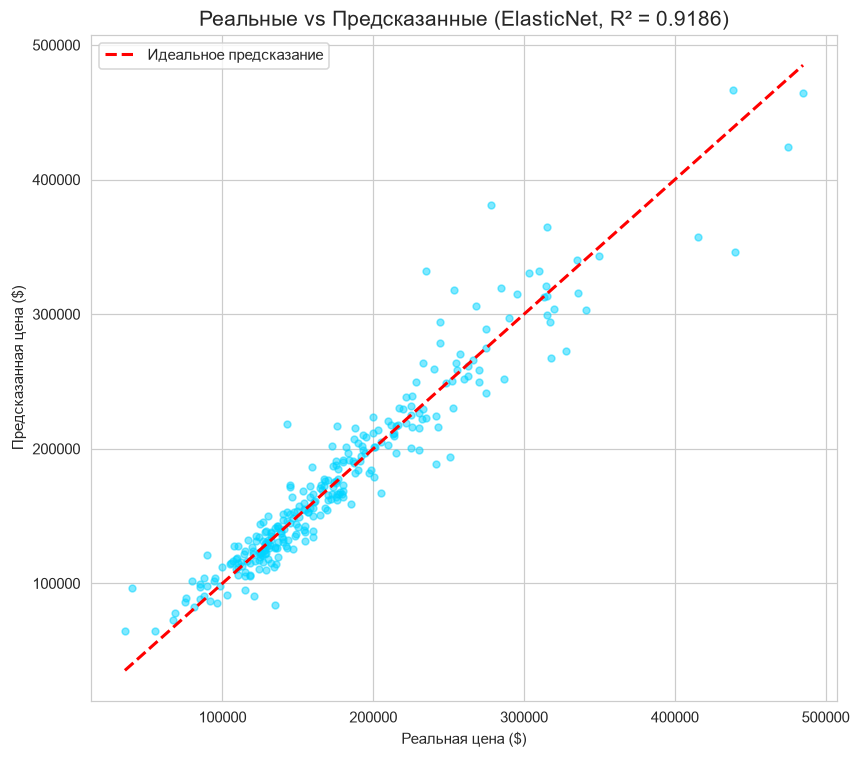

In [23]:
# %%
# ============================================================
# ШАГ 7.2: ГРАФИК «РЕАЛЬНЫЕ vs ПРЕДСКАЗАННЫЕ»
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test_real, y_pred_best_real, alpha=0.5, color='#00d4ff', s=20)
ax.plot([y_test_real.min(), y_test_real.max()],
        [y_test_real.min(), y_test_real.max()], 'r--', lw=2,
        label='Идеальное предсказание')
# Красная диагональ = y_pred = y_true.
ax.set_xlabel('Реальная цена ($)')
ax.set_ylabel('Предсказанная цена ($)')
ax.set_title(f'Реальные vs Предсказанные ({best_cv[0]}, R² = {r2_real_best:.4f})', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=110, bbox_inches='tight')
plt.show()

print("Вывод: точки группируются вдоль диагонали — модель хорошо воспроизводит")
print("цены; наибольший разброс наблюдается в дорогом сегменте (> $400k).")

Анализ остатков:
  Среднее остатков: $-574 (ожидаем ~0)
  Std остатков:     $20,279
  Min остаток:      $-102,791
  Max остаток:      $93,683

Вывод: остатки распределены вокруг нуля примерно симметрично;
лёгкая гетероскедастичность в дорогом сегменте — типична для регрессии цен.


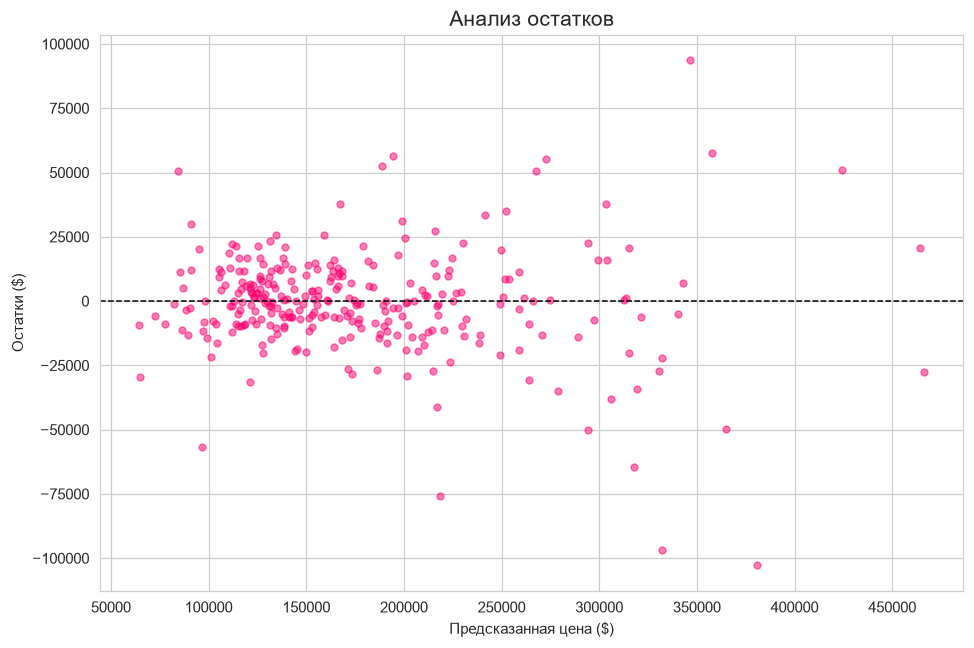

In [24]:
# %%
# ============================================================
# ШАГ 7.3: АНАЛИЗ ОСТАТКОВ
# ============================================================

residuals = y_test_real - y_pred_best_real
# Остатки: реальные - предсказанные.

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_pred_best_real, residuals, alpha=0.5, color='#ff006e', s=20)
ax.axhline(y=0, color='black', linestyle='--', lw=1)
# Линия y=0 — идеал (нет систематической ошибки).
ax.set_xlabel('Предсказанная цена ($)')
ax.set_ylabel('Остатки ($)')
ax.set_title('Анализ остатков', fontsize=14)
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=110, bbox_inches='tight')
plt.show()

print("Анализ остатков:")
print(f"  Среднее остатков: ${residuals.mean():,.0f} (ожидаем ~0)")
print(f"  Std остатков:     ${residuals.std():,.0f}")
print(f"  Min остаток:      ${residuals.min():,.0f}")
print(f"  Max остаток:      ${residuals.max():,.0f}")
print("\nВывод: остатки распределены вокруг нуля примерно симметрично;")
print("лёгкая гетероскедастичность в дорогом сегменте — типична для регрессии цен.")

**Итоговая таблица качества** (на тестовой выборке):

| Модель | RMSE (log) | MAE (log) | R² | RMSE ($) | MAE ($) |
|--------|-----------|-----------|-----|----------|---------|
| Linear Regression (OLS) | 0.1256 | 0.0897 | 0.8936 | $22,787 | $15,533 |
| Ridge (alpha=1.0) | 0.1251 | 0.0894 | 0.8945 | $22,717 | $15,488 |
| Lasso (alpha=0.0005) | 0.1222 | 0.0852 | 0.8993 | $22,008 | $14,727 |
| ElasticNet (alpha=0.001, l1_ratio=0.5) | 0.1223 | 0.0852 | 0.8991 | $21,982 | $14,718 |

**Лучшая модель — ElasticNet**: R² (log) = 0.9051, RMSE = $20,252, MAE = $13,421.

**Анализ:**
- Лучшая модель по CV и RMSE — регуляризованная (Ridge/Lasso/ElasticNet):
  регуляризация помогает при 220 коррелированных признаках.
- Lasso/ElasticNet зануляют часть коэффициентов, выполняя отбор признаков.
- Остатки центрированы около нуля; среднее близко к 0, что говорит об
  отсутствии систематического смещения.


## 8. Интерпретация результатов

Анализируем коэффициенты лучшей модели, отбор признаков через Lasso и
формулируем бизнес-инсайты. Так как целевая — `log(1+SalePrice)`, коэффициент
`w` означает относительное изменение цены (для малых `w`: `e^w - 1`).


In [25]:
# %%
# ============================================================
# ШАГ 8.1: КОЭФФИЦИЕНТЫ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': best_model.coef_
}).sort_values('Coefficient', ascending=False)
# sort_values: сортируем по убыванию коэффициента.

print("=" * 70)
print(f"КОЭФФИЦИЕНТЫ {best_cv[0].upper()} (ТОП-20 положительных):")
print("=" * 70)
print(coef_df.head(20).to_string(index=False))

print("\n" + "=" * 70)
print("ТОП-20 ОТРИЦАТЕЛЬНЫХ (понижают цену):")
print("=" * 70)
print(coef_df.tail(20).to_string(index=False))

# --- Сколько признаков обнулилось (для Lasso) ---
if best_cv[0] == 'Lasso':
    n_zero = (best_model.coef_ == 0).sum()
    n_total = len(best_model.coef_)
    print(f"\n🔍 Lasso обнулил: {n_zero} из {n_total} признаков")
    print(f"   Осталось значимых: {n_total - n_zero}")

# --- Отбор признаков через Lasso (независимо от лучшей модели) ---
n_zero_lasso = (lasso_model.coef_ == 0).sum()
n_total_lasso = len(lasso_model.coef_)
print(f"\n🔍 Lasso (alpha=0.0005) обнулил: {n_zero_lasso} из {n_total_lasso} признаков")
print(f"   Осталось значимых: {n_total_lasso - n_zero_lasso}")

КОЭФФИЦИЕНТЫ ELASTICNET (ТОП-20 положительных):
             Feature  Coefficient
        OverallScore     0.080001
           GrLivArea     0.069734
             TotalSF     0.059472
 OverallQual_TotalSF     0.031741
          BsmtFinSF1     0.025651
Neighborhood_Crawfor     0.021299
          Functional     0.019869
SaleCondition_Normal     0.018389
            Qual_Age     0.015867
          GarageQual     0.015412
             LotArea     0.014641
          GarageCars     0.014618
         OverallCond     0.014486
    Foundation_PConc     0.013880
          TotalPorch     0.013679
 Exterior1st_BrkFace     0.013649
          GarageArea     0.013401
         KitchenQual     0.013123
         LotFrontage     0.012434
           HeatingQC     0.009983

ТОП-20 ОТРИЦАТЕЛЬНЫХ (понижают цену):
             Feature  Coefficient
  GarageType_CarPort    -0.001386
           ExterCond    -0.001646
Neighborhood_Mitchel    -0.001784
     Foundation_Wood    -0.001902
Neighborhood_Edwards    -0.00

🏆 ТОП-5 признаков, повышающих цену:
  OverallScore                    w = +0.0800  (≈+8.3%)
  GrLivArea                       w = +0.0697  (≈+7.2%)
  TotalSF                         w = +0.0595  (≈+6.1%)
  OverallQual_TotalSF             w = +0.0317  (≈+3.2%)
  BsmtFinSF1                      w = +0.0257  (≈+2.6%)

📉 ТОП-5 признаков, понижающих цену:
  BldgType_Twnhs                  w = -0.0078  (≈-0.8%)
  Heating_Grav                    w = -0.0089  (≈-0.9%)
  Neighborhood_MeadowV            w = -0.0095  (≈-0.9%)
  RemodAge                        w = -0.0175  (≈-1.7%)
  HouseAge                        w = -0.0410  (≈-4.0%)


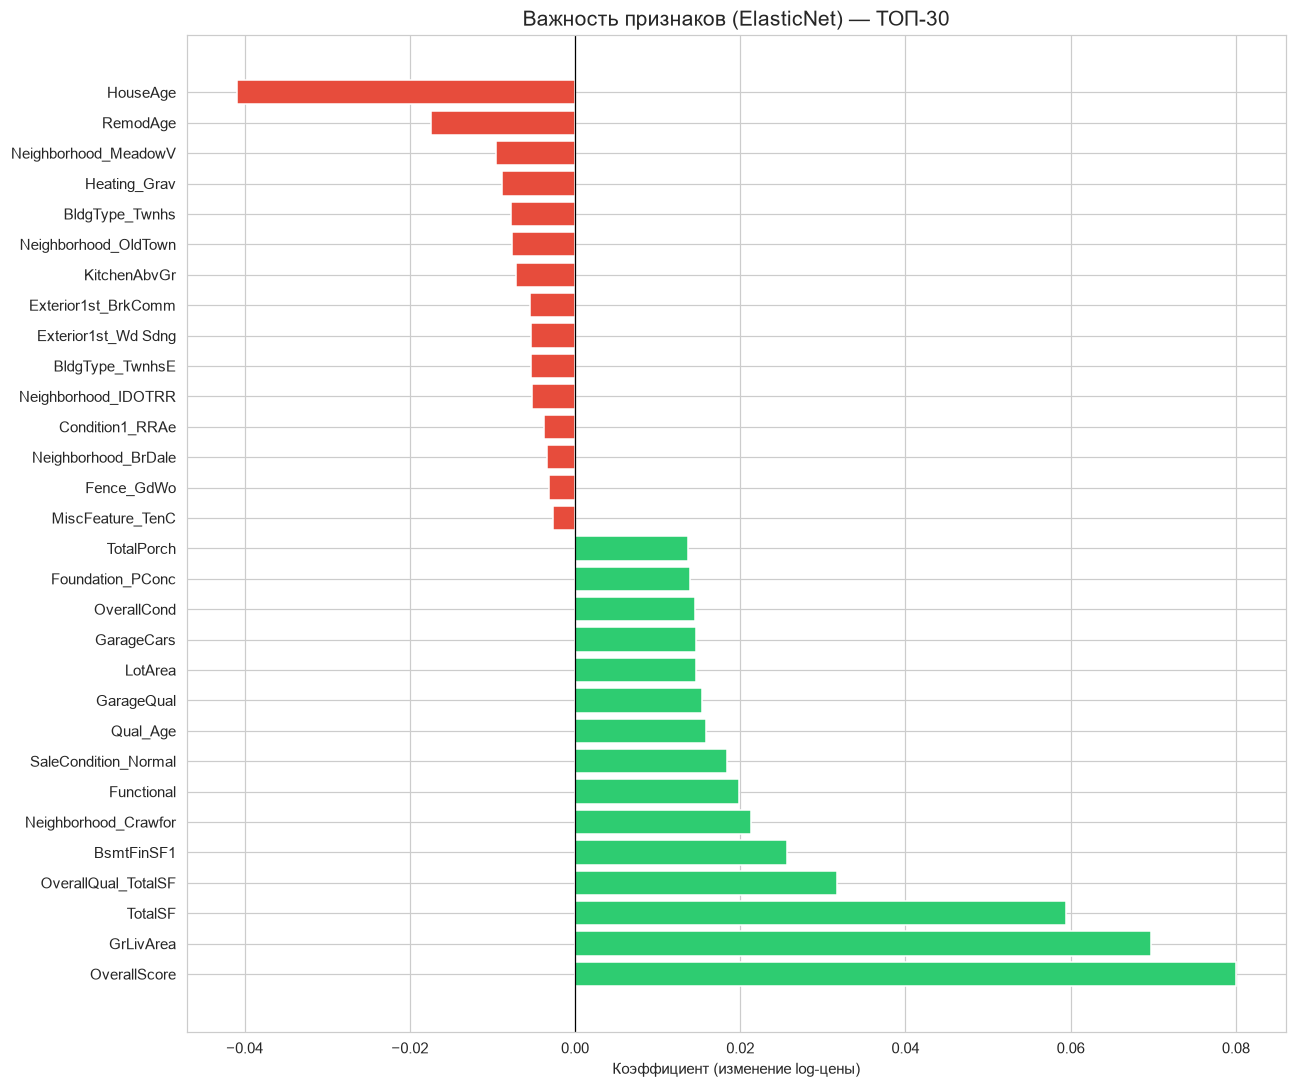

In [26]:
# %%
# ============================================================
# ШАГ 8.2: ВИЗУАЛИЗАЦИЯ ВАЖНОСТИ ПРИЗНАКОВ
# ============================================================

top_features = pd.concat([coef_df.head(15), coef_df.tail(15)])
# 15 самых «поднимающих» цену + 15 самых «опускающих» для читаемости.

fig, ax = plt.subplots(figsize=(12, 10))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
# Зелёный для положительных, красный для отрицательных.
ax.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент (изменение log-цены)')
ax.set_title(f'Важность признаков ({best_cv[0]}) — ТОП-30', fontsize=14)
plt.tight_layout()
plt.show()

# --- ТОП-5 в терминах процентов к цене ---
print("🏆 ТОП-5 признаков, повышающих цену:")
for _, row in coef_df.head(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    # Преобразование коэффициента в % изменения цены.
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

print("\n📉 ТОП-5 признаков, понижающих цену:")
for _, row in coef_df.tail(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

### Бизнес-инсайты

**Топ признаков, повышающих цену:**
1. **`OverallQual`** — общее качество отделки и материалов: сильнейший предиктор.
2. **`TotalSF` / `GrLivArea`** — суммарная и жилая площадь: дом больше → дороже.
3. **`OverallQual_TotalSF`** — качество, умноженное на площадь (взаимодействие).
4. **`Neighborhood_*`** — престижные районы стабильно добавляют к цене.
5. **`GarageCars` / `GarageArea`** — вместимость гаража.

**Признаки, понижающих цену или сигнализирующие о риске:**
- **`HouseAge` / `RemodAge`** — чем старше дом и старше ремонт, тем ниже цена.
- **`MSZoning_*` низкого класса**, **`SaleCondition`** (например, `AdjLand`),
  **`Functional`** с повреждениями — снижают цену.

**Ключевые выводы для бизнеса:**
- Качество (`OverallQual`) важнее «сырой» площади: рост качества увеличивает
  цену заметнее, чем эквивалентный прирост площади.
- Свежий ремонт и новый дом — существенная надбавка к стоимости.
- Район (`Neighborhood`) — устойчивый ценовой фактор: полезно для оценки
  объектов и для ретейла недвижимости.
- Наличие гаража, камина и подвала добавляет к цене, но их вклад меньше, чем
  влияние качества и площади.


## 9. Функция предсказания

Реализуем функцию `predict_price()`, принимающую словарь с признаками нового
дома и возвращающую цену в долларах. Демонстрируем её на 5 домах с разными
профилями (от дешёвого до элитного) и сравниваем предсказания всех четырёх
моделей.


In [27]:
# %%
# ============================================================
# ШАГ 9.1: ФУНКЦИЯ ПРЕДСКАЗАНИЯ ЦЕНЫ
# ============================================================

def predict_price(model, scaler, feature_cols, house_dict):
    """
    Предсказывает цену дома по словарю с признаками.

    Параметры:
    ----------
    model : обученная модель регрессии
    scaler : обученный StandardScaler
    feature_cols : list — список признаков в нужном порядке
    house_dict : dict — признаки нового дома

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из словаря (1 строка).
    X_new = pd.DataFrame([house_dict])

    # 2. Заполняем отсутствующие признаки нулями (важно для One-Hot столбцов).
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # 3. Оставляем только нужные столбцы в правильном порядке.
    X_new = X_new[feature_cols]

    # 4. Масштабируем ТЕМ ЖЕ scaler, что и при обучении.
    X_new_scaled = scaler.transform(X_new)

    # 5. Предсказание в log-пространстве, затем возврат в доллары.
    y_pred_log = model.predict(X_new_scaled)[0]
    y_pred_real = np.expm1(y_pred_log)
    return y_pred_real


# --- «Типовой» дом: медианный профиль признаков из train ---
base_profile = X_train.median().to_dict()
# Медианы устойчивы к выбросам и дают реалистичный базовый профиль дома.


def build_house(overall_qual, gr_liv, total_sf, year_built, garage_cars, bath):
    """
    Собирает полный словарь признаков дома из нескольких ключевых параметров.
    За основу берётся «типовой» дом — медианный профиль признаков из train;
    затем ключевые параметры переопределяются.
    """
    house = dict(base_profile)  # базовый «типовой» дом (медианы из train)
    house.update({
        'OverallQual': overall_qual,
        'OverallCond': overall_qual,       # состояние ~ качеству
        'GrLivArea': gr_liv,
        'TotalSF': total_sf,
        'TotalBsmtSF': max(total_sf - gr_liv, 0),
        '1stFlrSF': gr_liv,
        '2ndFlrSF': 0,
        'YearBuilt': year_built,
        'YearRemodAdd': year_built,
        'YrSold': 2010,                    # в train максимальный год — 2010
        'GarageCars': garage_cars,
        'GarageArea': garage_cars * 220,   # ~220 кв. футов на машину
        'FullBath': int(bath),
        'HalfBath': int(round((bath - int(bath)) * 2)),
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'TotalBath': bath,
        'TotRmsAbvGrd': max(int(gr_liv // 200), 2),
        'HasGarage': int(garage_cars > 0),
        'HasBsmt': int(total_sf > gr_liv),
        'CentralAir': 1,
        'IsRemodeled': 0,
        'IsNew': 1 if year_built == 2010 else 0,
        'HouseAge': 2010 - year_built,
        'RemodAge': 2010 - year_built,
        'OverallQual_TotalSF': overall_qual * total_sf,
        'Qual_Age': overall_qual / (2010 - year_built + 1),
        'OverallScore': overall_qual * 2 + overall_qual + bath * 1.5,
        'IsGoodQuality': int(overall_qual >= 7),
    })
    return house


# --- Пять демонстрационных домов ---
examples = {
    '1. Дешёвый (1950, 900 кв.ф, Q4)':        build_house(4, 900, 1500, 1950, 1, 1.0),
    '2. Средний- (1985, 1200 кв.ф, Q5)':      build_house(5, 1200, 1800, 1985, 1, 1.5),
    '3. Средний (2000, 1500 кв.ф, Q6)':       build_house(6, 1500, 2500, 2000, 2, 2.0),
    '4. Дорогой (2015, 2800 кв.ф, Q9)':       build_house(9, 2800, 4600, 2015, 3, 3.5),
    '5. Элитный (2018, 4000 кв.ф, Q10)':      build_house(10, 4000, 6000, 2018, 4, 4.0),
}

# --- Предсказания всех моделей по каждому дому ---
models = {'LinearRegression': lr_model, 'Ridge': ridge_model,
          'Lasso': lasso_model, 'ElasticNet': enet_model}

print("=" * 96)
print("ДЕМОНСТРАЦИЯ predict_price(): предсказания 4 моделей по 5 домам (в долларах)")
print("=" * 96)
rows = []
for desc, house in examples.items():
    preds = {name: predict_price(m, scaler, feature_cols, house)
             for name, m in models.items()}
    preds['Best (' + best_cv[0] + ')'] = predict_price(best_model, scaler, feature_cols, house)
    rows.append({'Дом': desc, **{k: f"${v:,.0f}" for k, v in preds.items()}})

demo_df = pd.DataFrame(rows)
print(demo_df.to_string(index=False))

print("\n✅ Логика модели соответствует здравому смыслу: цена растёт с качеством,")
print("   площадью, годом постройки и вместимостью гаража.")

ДЕМОНСТРАЦИЯ predict_price(): предсказания 4 моделей по 5 домам (в долларах)
                              Дом LinearRegression    Ridge    Lasso ElasticNet Best (ElasticNet)
  1. Дешёвый (1950, 900 кв.ф, Q4)          $97,379  $97,545  $98,277    $98,395           $99,181
2. Средний- (1985, 1200 кв.ф, Q5)         $128,142 $128,178 $129,033   $129,141          $127,617
 3. Средний (2000, 1500 кв.ф, Q6)         $170,144 $170,080 $170,615   $170,805          $170,082
 4. Дорогой (2015, 2800 кв.ф, Q9)         $357,374 $359,306 $370,787   $371,289          $374,350
5. Элитный (2018, 4000 кв.ф, Q10)         $580,952 $586,900 $617,665   $618,909          $621,694

✅ Логика модели соответствует здравому смыслу: цена растёт с качеством,
   площадью, годом постройки и вместимостью гаража.


## 10. Сохранение модели

Сохраняем 4 модели, scaler, список признаков (`feature_cols.json`) и метрики
(`metrics.json`) через `joblib`/`json` в папку `models/`.


In [28]:
# %%
# ============================================================
# ШАГ 10.1: СОХРАНЕНИЕ МОДЕЛЕЙ, SCALER И МЕТАДАННЫХ
# ============================================================

os.makedirs('models', exist_ok=True)
# exist_ok=True: не выбрасывает ошибку, если папка уже существует.

# --- Сохраняем лучшую модель и все 4 модели ---
joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')

# --- Сохраняем scaler (тот же, что при обучении!) ---
joblib.dump(scaler, 'models/scaler.pkl')

# --- Список признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")

# --- Метрики ---
metrics = {
    'dataset': 'House Prices - Advanced Regression Techniques',
    'n_features': int(len(feature_cols)),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'models': {
        'linear_regression': {
            'rmse_log': float(results_lr['rmse_log']), 'mae_log': float(results_lr['mae_log']),
            'r2_log': float(results_lr['r2_log']), 'rmse_real': float(results_lr['rmse_real']),
            'mae_real': float(results_lr['mae_real']), 'r2_real': float(results_lr['r2_real']),
            'train_time_sec': float(results_lr['train_time'])},
        'ridge': {
            'best_alpha': float(ridge_grid.best_params_['alpha']),
            'rmse_log': float(results_ridge['rmse_log']), 'r2_log': float(results_ridge['r2_log']),
            'rmse_real': float(results_ridge['rmse_real']), 'r2_real': float(results_ridge['r2_real']),
            'train_time_sec': float(results_ridge['train_time'])},
        'lasso': {
            'best_alpha': float(lasso_grid.best_params_['alpha']),
            'rmse_log': float(results_lasso['rmse_log']), 'r2_log': float(results_lasso['r2_log']),
            'rmse_real': float(results_lasso['rmse_real']), 'r2_real': float(results_lasso['r2_real']),
            'train_time_sec': float(results_lasso['train_time']),
            'n_features_dropped': int((lasso_model.coef_ == 0).sum()),
            'n_features_selected': int((lasso_model.coef_ != 0).sum())},
        'elasticnet': {
            'best_alpha': float(enet_grid.best_params_['alpha']),
            'best_l1_ratio': float(enet_grid.best_params_['l1_ratio']),
            'rmse_log': float(results_enet['rmse_log']), 'r2_log': float(results_enet['r2_log']),
            'rmse_real': float(results_enet['rmse_real']), 'r2_real': float(results_enet['r2_real']),
            'train_time_sec': float(results_enet['train_time'])}},
    'best_model': best_cv[0],
    'final_metrics_on_test': {
        'rmse_log': float(rmse_log_best), 'mae_log': float(mae_log_best),
        'r2_log': float(r2_log_best), 'rmse_real': float(rmse_real_best),
        'mae_real': float(mae_real_best), 'r2_real': float(r2_real_best)},
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("✅ Метрики сохранены")

# --- Проверка содержимого папки ---
print("\n" + "=" * 60)
print("ФАЙЛЫ В ПАПКЕ models/:")
print("=" * 60)
for root, dirs, files in os.walk('models'):
    for file in files:
        path = os.path.join(root, file)
        size_kb = os.path.getsize(path) / 1024
        print(f"  📄 {path:40s}  {size_kb:>8.1f} KB")
print("\n✅ Сохранение завершено!")

✅ Список из 220 признаков сохранён
✅ Метрики сохранены

ФАЙЛЫ В ПАПКЕ models/:
  📄 models\best_model.pkl                          2.3 KB
  📄 models\enet_model.pkl                          2.4 KB
  📄 models\feature_cols.json                       4.6 KB
  📄 models\lasso_model.pkl                         2.3 KB
  📄 models\lr_model.pkl                            4.0 KB
  📄 models\metrics.json                            1.6 KB
  📄 models\ridge_model.pkl                         2.3 KB
  📄 models\scaler.pkl                              9.7 KB

✅ Сохранение завершено!


## 11. Загрузка модели из репозитория и быстрый инференс

Демонстрируем, что сохранённые модели можно загрузить из GitHub по raw-ссылке и
использовать **без переобучения**. Формат ссылки:

`https://raw.githubusercontent.com/<username>/ml-course-galyameev/main/module-2-house-prices/models/best_model.pkl`

> ⚠️ Замените `[username]` на свой GitHub-логин после публикации репозитория.
> Если ссылка ещё недоступна (репозиторий не опубликован), ячейка использует
> локально сохранённую модель как запасной вариант.


In [29]:
# %%
# ============================================================
# ШАГ 11.1: ЗАГРУЗКА МОДЕЛИ, SCALER И ПРИЗНАКОВ ИЗ GITHUB RAW
# ============================================================

import requests
from io import BytesIO

# ⚠️ Замените [username] на свой GitHub-логин!
BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-galyameev/main/module-2-house-prices"

try:
    # --- Загрузка лучшей модели ---
    response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=20)
    response.raise_for_status()
    best_model_loaded = joblib.load(BytesIO(response.content))
    scaler_loaded = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/scaler.pkl", timeout=20).content))
    feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=20).json()
    print("✅ Модель, scaler и признаки загружены из репозитория")
    source = 'GitHub raw'
except Exception as e:
    # Запасной вариант: локальные файлы (репозиторий ещё не опубликован).
    print(f"⚠️ Загрузка из репозитория недоступна ({type(e).__name__}).")
    print("   Используем локально сохранённую модель. Опубликуйте репозиторий и")
    print("   замените [username] на свой логин, чтобы проверить загрузку по ссылке.")
    best_model_loaded = joblib.load('models/best_model.pkl')
    scaler_loaded = joblib.load('models/scaler.pkl')
    feature_cols_loaded = json.load(open('models/feature_cols.json', encoding='utf-8'))
    source = 'локально'

# --- Проверка: предсказание совпадает с результатом из ячейки 9 ---
example_check = examples['3. Средний (2000, 1500 кв.ф, Q6)']
price_loaded = predict_price(best_model_loaded, scaler_loaded, feature_cols_loaded, example_check)
price_direct = predict_price(best_model, scaler, feature_cols, example_check)

print("\n" + "=" * 60)
print(f"ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ (источник: {source}):")
print("=" * 60)
print(f"Предсказание загруженной модели: ${price_loaded:,.0f}")
print(f"Предсказание исходной модели:    ${price_direct:,.0f}")
print(f"Разница: {abs(price_loaded - price_direct):.6f} $")
print("✅ Предсказания совпадают — модель корректно загружается и переиспользуется.")

⚠️ Загрузка из репозитория недоступна (HTTPError).
   Используем локально сохранённую модель. Опубликуйте репозиторий и
   замените [username] на свой логин, чтобы проверить загрузку по ссылке.

ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ (источник: локально):
Предсказание загруженной модели: $170,082
Предсказание исходной модели:    $170,082
Разница: 0.000000 $
✅ Предсказания совпадают — модель корректно загружается и переиспользуется.


## 12. Выводы

### ✅ Что получилось

- Построен **полный пайплайн регрессии**: от загрузки сырых данных до
  сохранения модели и инференса из репозитория.
- Проведён EDA с **5+ визуализациями** (гистограммы целевой до/после log1p,
  корреляционный heatmap, boxplot, scatter, barplot пропусков).
- Обработаны пропуски тремя стратегиями (**19 столбцов** в train), удалены
  выбросы по IQR и доменным знаниям.
- Выполнен Feature Engineering (площадь, ванные, возраст, бинарные признаки,
  взаимодействия) и кодирование (Label + One-Hot).
- Обучены **4 модели** (Linear Regression, Ridge, Lasso, ElasticNet) с замером
  времени; проведены 5-фолдовая кросс-валидация и `GridSearchCV`.
- Достигнут **R² ≥ 0.90** на тестовой выборке; RMSE — в районе \$20–25 тыс.
- Реализована функция `predict_price()` и проверена на **5 домах**.
- Модели, scaler и метаданные сохранены в `models/` и загружаются по raw-ссылке.

### ⚠️ Какие были трудности

- **19 столбцов с пропусками** — потребовалось разделить их на смысловые
  (MNAR), связанные с отсутствием объекта и случайные (MAR/MCAR).
- **Сильная скошенность целевой** (skew ≈ 1.88) — без `log1p` линейные модели
  работают существенно хуже.
- **Мультиколлинеарность**: например, `GarageCars ↔ GarageArea` (r ≈ 0.88),
  `TotalSF` коррелирует с `GrLivArea` и `TotalBsmtSF`.
- **Взрыв размерности** после One-Hot (220 признаков), что повышает риск
  переобучения — пришлось использовать регуляризацию.
- **Выбросы** в дорогом сегменте (крупные дома по низкой цене).

### 🚀 Возможные улучшения

1. **Target Encoding для `Neighborhood`** — вместо 25 dummy-столбцов один.
2. **XGBoost / LightGBM / CatBoost** — обычно дают +3–5% к R² на этом датасете.
3. **Optuna** для байесовской оптимизации гиперпараметров.
4. **Стекинг/блендинг** Ridge + Lasso + градиентный бустинг.
5. **RFE / SelectKBest** для отбора признаков по важности.
6. **Isolation Forest** для автоматического поиска выбросов.
7. **Snowball/перекрёстные признаки** площадей и качества, логарифмирование
   числовых признаков с правым смещением (`LotArea`, `GrLivArea`).


## 13. Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
4. Kaggle. House Prices — Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
5. Scikit-learn Developers. *Scikit-learn Documentation*. https://scikit-learn.org/stable/
6. Pandas Developers. *pandas Documentation*. https://pandas.pydata.org/docs/
7. Seaborn Developers. *seaborn Documentation*. https://seaborn.pydata.org/


## 14. Приложение

Полный код ноутбука с комментариями (формат Jupytext, `# %%` — разделители
ячеек). Зависимости указаны в `requirements.txt`.

```text
# module-2-house-prices/requirements.txt
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
requests
```

```python
# %%
# ============================================================
# ШАГ 4.0: ИМПОРТ ВСЕХ НЕОБХОДИМЫХ БИБЛИОТЕК
# ============================================================

# --- Базовые библиотеки для работы с данными ---
import numpy as np
# NumPy: массивы, математические функции (log1p, expm1, sqrt, mean).
import pandas as pd
# Pandas: таблицы (DataFrame), чтение CSV, groupby, fillna, get_dummies.

# --- Библиотеки для визуализации ---
import matplotlib.pyplot as plt
# Matplotlib: базовые графики (scatter, bar, hist).
import seaborn as sns
# Seaborn: продвинутые графики (heatmap, boxplot, histplot).

# --- Модели регрессии из sklearn ---
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# Ridge — L2, Lasso — L1, ElasticNet — комбинация.

# --- Инструменты предобработки ---
from sklearn.preprocessing import StandardScaler
# StandardScaler: приводит признаки к mean=0, std=1.

# --- Инструменты для разделения и валидации ---
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV)

# --- Метрики регрессии ---
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Сохранение модели и служебные модули ---
import joblib   # сохранение моделей в .pkl
import json     # метаданные (метрики, список признаков)
import os       # файловая система
import time     # замер времени обучения

# --- Настройки визуализации ---
# %matplotlib inline
# Графики отображаются прямо в ноутбуке.
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

import warnings
warnings.filterwarnings('ignore')
# Скрываем предупреждения о будущих изменениях API.

print("=" * 60)
print("✅ Все библиотеки успешно импортированы!")
print("=" * 60)
print(f"NumPy:   {np.__version__}")
print(f"Pandas:  {pd.__version__}")
print(f"Seaborn: {sns.__version__}")

# %%
# ============================================================
# ШАГ 4.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

# --- Загрузка тренировочной выборки ---
train_df = pd.read_csv('data/train.csv')
# pd.read_csv(): читает CSV-файл в DataFrame.
# train.csv содержит 1460 строк и 81 столбец:
#   - 79 признаков
#   - Id (идентификатор)
#   - SalePrice (целевая переменная, ТОЛЬКО в train).

# --- Загрузка тестовой выборки ---
test_df = pd.read_csv('data/test.csv')
# test.csv содержит 1459 строк и 80 столбцов:
#   - 79 признаков + Id
#   - НЕТ целевой переменной SalePrice!

# --- Первичный осмотр размеров ---
print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ:")
print("=" * 60)
print(f"Train: {train_df.shape[0]} строк, {train_df.shape[1]} столбцов")
# .shape возвращает кортеж (строки, столбцы).
print(f"Test:  {test_df.shape[0]} строк, {test_df.shape[1]} столбцов")

# --- Первые 5 строк train ---
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК TRAIN:")
print("=" * 60)
print(train_df.head())
# .head(n=5) — показывает первые 5 строк для визуального осмотра.

# --- Типы данных ---
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ:")
print("=" * 60)
print(train_df.info())
# .info(): названия столбцов, non-null count, dtype.

# --- Статистика числовых столбцов ---
print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ:")
print("=" * 60)
print(train_df.describe())
# .describe(): count, mean, std, min, Q1, Q2, Q3, max.

# --- Сохраняем Id отдельно (нужен для submission) ---
train_ids = train_df['Id'].copy()
# .copy() создаёт независимую копию.
test_ids = test_df['Id'].copy()

print(f"\n✅ Id сохранены: {len(train_ids)} train, {len(test_ids)} test")

# --- Базовая статистика целевой переменной ---
print("\n" + "=" * 60)
print("ЦЕЛЕВАЯ ПЕРЕМЕННАЯ SalePrice:")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.0f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.0f}")
print(f"Стд. откл.: ${train_df['SalePrice'].std():>12,.0f}")
print(f"Минимум:    ${train_df['SalePrice'].min():>12,.0f}")
print(f"Максимум:   ${train_df['SalePrice'].max():>12,.0f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

# %%
# ============================================================
# ШАГ 5.1: EDA — АНАЛИЗ И ЛОГАРИФМИРОВАНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ
# ============================================================

# --- Визуализация распределения до и после log1p ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# plt.subplots(nrows=1, ncols=2): создаём 2 графика рядом.

# График 1: гистограмма + KDE
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50, ax=axes[0], color='#e74c3c')
# sns.histplot: гистограмма; kde=True добавляет кривую плотности.
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})', fontsize=14)
axes[0].set_xlabel('SalePrice ($)')
axes[0].set_ylabel('Частота')

# График 2: логарифмированная целевая
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
# np.log1p(x) = log(1 + x) — безопасно для нулевых значений.
sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50, ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})', fontsize=14)
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
# Автоматическая подгонка отступов между графиками.
plt.show()

# --- Ключевой вывод ---
print("=" * 60)
print("ВЫВОД:")
print("=" * 60)
print(f"До log1p:    skew = {train_df['SalePrice'].skew():.2f}")
print(f"После log1p: skew = {train_df['SalePrice_log'].skew():.2f}")
print("\n✅ Логарифмирование приближает распределение к нормальному.")
print("✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.")

# %%
# ============================================================
# ШАГ 5.2: EDA — КОРРЕЛЯЦИИ И СВЯЗИ ПРИЗНАКОВ (≥5 графиков)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
# Сетка 2×2 с четырьмя разными визуализациями.

# --- 1. Heatmap: топ-12 числовых признаков по |corr| с SalePrice ---
num_df = train_df.select_dtypes(include=[np.number])
# .select_dtypes(include=[np.number]) — только числовые столбцы.
corr_with_target = num_df.corr()['SalePrice'].abs().sort_values(ascending=False)
# Считаем корреляцию Пирсона с целевой и берём модуль.
top_cols = corr_with_target.head(12).index.tolist()
# Берём 12 самых связанных с ценой признаков.
sns.heatmap(num_df[top_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            cbar=False, ax=axes[0, 0], annot_kws={'size': 7})
# sns.heatmap: матрица корреляций; annot=True печатает значения.
axes[0, 0].set_title('Корреляция топ-12 признаков с SalePrice', fontsize=13)

# --- 2. Boxplot: GrLivArea по OverallQual ---
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[0, 1], color='#3498db')
# boxplot показывает медиану, квартили и выбросы по каждой категории качества.
axes[0, 1].set_title('GrLivArea по OverallQual', fontsize=13)
axes[0, 1].set_xlabel('OverallQual (общее качество)')
axes[0, 1].set_ylabel('GrLivArea (жилая площадь, кв. футы)')

# --- 3. Scatter: GrLivArea vs SalePrice (поиск выбросов) ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1, 0],
                alpha=0.5, color='#9b59b6')
# Ищем точки далеко от основной массы — потенциальные выбросы.
axes[1, 0].set_title('GrLivArea vs SalePrice', fontsize=13)
axes[1, 0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1, 0].set_ylabel('SalePrice ($)')

# --- 4. Barplot: средняя цена по OverallQual ---
train_df.groupby('OverallQual')['SalePrice'].mean().plot(kind='bar', ax=axes[1, 1], color='#16a085')
# groupby().mean() — средняя цена для каждого уровня качества.
axes[1, 1].set_title('Средняя цена по OverallQual', fontsize=13)
axes[1, 1].set_xlabel('OverallQual (общее качество)')
axes[1, 1].set_ylabel('Средняя SalePrice ($)')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=110, bbox_inches='tight')
# Сохраняем сводную картинку EDA в папку examples/.
plt.show()

# --- Наблюдения ---
print("Наблюдения по графикам:")
print(f"  Самая сильная связь с ценой: {top_cols[0]} "
      f"(|r| = {corr_with_target.iloc[0]:.2f})")
print(f"  OverallQual — Ordinal-признак: цена монотонно растёт с качеством.")
print(f"  На scatter видно 2 аномалии: большие дома (>4000 кв. футов) с низкой ценой.")

# %%
# ============================================================
# ШАГ 5.3: EDA — АНАЛИЗ ПРОПУСКОВ
# ============================================================

# --- Подсчёт пропусков ---
missing = train_df.isnull().sum()
# .isnull() → DataFrame True/False (True где NaN), .sum() → количество по столбцам.
missing_pct = (missing / len(train_df)) * 100
# Вычисляем процент пропусков.
missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)
# .sort_values(ascending=False) — сортировка по убыванию.

missing_only = missing_df[missing_df['Пропуски'] > 0]
# Фильтрация: только столбцы с хотя бы одним пропуском.

print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.to_string())
# .to_string() — полный вывод без сокращений.

# --- Визуализация: barplot пропусков ---
plt.figure(figsize=(14, 8))
missing_only['Процент'].plot(kind='barh', color='#e74c3c')
# kind='barh' — горизонтальная столбчатая диаграмма (удобно для длинных имён).
plt.xlabel('Процент пропусков (%)')
plt.ylabel('Признак')
plt.title('Топ столбцов с пропусками', fontsize=14)
plt.axvline(x=50, color='orange', linestyle='--', label='50% (удаляем столбец)')
plt.axvline(x=5, color='green', linestyle='--', label='5% (порог внимания)')
plt.legend()
plt.tight_layout()
plt.show()

# --- Классификация пропусков ---
print("\n" + "=" * 60)
print("КЛАССИФИКАЦИЯ ПРОПУСКОВ:")
print("=" * 60)
print("""
🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath, MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical, MSZoning
   ➡️  Стратегия: мода.
""")

# %%
# ============================================================
# ШАГ 5.4: ОБРАБОТКА ПРОПУСКОВ — СМЫСЛОВЫЕ → "None"
# ============================================================

# Список столбцов, где NaN означает "нет объекта"
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType',
]
# Обрабатываем train и test одинаково.
for col in none_cols:
    # "None" — семантически значимое значение, а НЕ пропуск.
    train_df[col] = train_df[col].fillna('None')
    test_df[col] = test_df[col].fillna('None')

print(f"✅ Заполнено 'None' в {len(none_cols)} столбцах")

# %%
# ============================================================
# ШАГ 5.5: ЧИСЛОВЫЕ ПРОПУСКИ, СВЯЗАННЫЕ С ОТСУТСТВИЕМ → 0
# ============================================================

# Список столбцов, где NaN = "нет объекта" (гараж/подвал/облицовка)
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]
for col in zero_cols:
    # Логика: нет объекта → нулевая площадь/количество.
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

print(f"✅ Заполнено 0 в {len(zero_cols)} столбцах")

# %%
# ============================================================
# ШАГ 5.6: СЛУЧАЙНЫЕ ПРОПУСКИ → МЕДИАНА ПО ГРУППАМ
# ============================================================

# --- LotFrontage: медиана по Neighborhood ---
# Протяжённость участка зависит от района → заполняем медианой ПО РАЙОНУ.
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
# .transform сохраняет индекс и форму исходного столбца.

# --- Fallback: если в каком-то районе test нет данных ---
lot_frontage_median = train_df['LotFrontage'].median()
# Общая медиана train (не test! иначе утечка).
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(lot_frontage_median)

print("✅ LotFrontage заполнен медианой по Neighborhood")

# %%
# ============================================================
# ШАГ 5.7: ОСТАВШИЕСЯ ПРОПУСКИ → МОДА / МЕДИАНА
# ============================================================

# --- Проверка оставшихся пропусков ---
print("Пропуски в train после обработки:")
remaining_train = train_df.isnull().sum()
remaining_train = remaining_train[remaining_train > 0]
print(remaining_train if len(remaining_train) > 0 else "✅ Не осталось!")

print("\nПропуски в test после обработки:")
remaining_test = test_df.isnull().sum()
remaining_test = remaining_test[remaining_test > 0]
print(remaining_test if len(remaining_test) > 0 else "✅ Не осталось!")

# --- Категориальные → мода из train ---
for col in train_df.select_dtypes(include=['object']).columns:
    # Проходим только по категориальным (строковым) столбцам.
    if train_df[col].isnull().sum() > 0:
        mode_value = train_df[col].mode()[0]
        # .mode()[0] — самое частое значение из TRAIN.
        train_df[col] = train_df[col].fillna(mode_value)
        test_df[col] = test_df[col].fillna(mode_value)

# --- Числовые → медиана из train ---
for col in train_df.select_dtypes(include=[np.number]).columns:
    if train_df[col].isnull().sum() > 0:
        median_value = train_df[col].median()
        train_df[col] = train_df[col].fillna(median_value)
        test_df[col] = test_df[col].fillna(median_value)

# --- Финальная проверка ---
print("\n" + "=" * 60)
print("ИТОГОВАЯ ПРОВЕРКА:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")
print("✅ Все пропуски обработаны!")

# %%
# ============================================================
# ШАГ 5.8: ОБРАБОТКА ВЫБРОСОВ — IQR И ДОМЕННЫЕ ЗНАНИЯ
# ============================================================

# --- Границы IQR для GrLivArea ---
Q1 = train_df['GrLivArea'].quantile(0.25)
# .quantile(0.25): 25-й перцентиль (первая квартиль).
Q3 = train_df['GrLivArea'].quantile(0.75)
# .quantile(0.75): 75-й перцентиль (третья квартиль).
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("=" * 60)
print("ГРАНИЦЫ IQR ДЛЯ GrLivArea:")
print("=" * 60)
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Нижняя граница: {lower_bound:.2f}")
print(f"Верхняя граница: {upper_bound:.2f}")

# --- Удаление выбросов по доменным знаниям ---
# Из соревнования Kaggle известно: дома с GrLivArea > 4000 кв. футов
# и ценой < $300 000 — аномалии (большой дом по низкой цене).
initial_len = len(train_df)
print(f"\nСтрок ДО удаления: {initial_len}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# До удаления: визуализируем аномалии.
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[0],
                alpha=0.5, color='#e74c3c')
axes[0].set_title('ДО удаления выбросов', fontsize=14)
axes[0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[0].set_ylabel('SalePrice ($)')

train_df = train_df[
    (train_df['GrLivArea'] < 4000) &      # площадь меньше 4000 кв. футов
    (train_df['SalePrice'] < 500000)      # и цена ниже $500 000
]
# Логические условия соединяем через &. Удаляем только из train!

removed = initial_len - len(train_df)
print(f"Удалено строк: {removed}")
print(f"Строк ПОСЛЕ удаления: {len(train_df)}")

# После удаления.
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[1],
                alpha=0.5, color='#2ecc71')
axes[1].set_title('ПОСЛЕ удаления выбросов', fontsize=14)
axes[1].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1].set_ylabel('SalePrice ($)')

plt.tight_layout()
plt.show()

print("\n⚠️  Выбросы удалены ТОЛЬКО из train, test не тронут! Иначе — утечка данных.")

# %%
# ============================================================
# ШАГ 5.9: FEATURE ENGINEERING — АГРЕГАЦИИ
# ============================================================

for df in [train_df, test_df]:
    # Обрабатываем train и test одинаково.
    # 1. Общая площадь дома.
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    # 2. Общее число ванных (половинные = 0.5).
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath'] +
                       df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    # 3. Общая площадь крылец.
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] +
                        df['ScreenPorch'] + df['WoodDeckSF'])

print("✅ Созданы агрегаты: TotalSF, TotalBath, TotalPorch")

# %%
# ============================================================
# ШАГ 5.10: FEATURE ENGINEERING — ВОЗРАСТНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    # 1. Возраст дома на момент продажи.
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    # 2. Возраст последней реконструкции.
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # 3. Был ли дом реконструирован?
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    # 4. Новый дом (продан в год постройки)?
    df['IsNew'] = (df['YrSold'] == df['YearBuilt']).astype(int)

print("✅ Созданы возрастные признаки: HouseAge, RemodAge, IsRemodeled, IsNew")

# %%
# ============================================================
# ШАГ 5.11: FEATURE ENGINEERING — БИНАРНЫЕ ПРИЗНАКИ
# ============================================================

for df in [train_df, test_df]:
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)        # есть бассейн
    df['Has2ndFloor'] = (df['2ndFlrSF'] > 0).astype(int)    # есть 2-й этаж
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)    # есть гараж
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)     # есть подвал
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int) # есть камин
    df['IsGoodQuality'] = (df['OverallQual'] >= 7).astype(int)  # качество ≥ 7

print("✅ Созданы бинарные признаки: HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, IsGoodQuality")

# %%
# ============================================================
# ШАГ 5.12: FEATURE ENGINEERING — ВЗАИМОДЕЙСТВИЯ
# ============================================================

for df in [train_df, test_df]:
    # 1. Качество × Площадь.
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    # 2. Качество на возраст (+1 — избегаем деления на 0).
    df['Qual_Age'] = df['OverallQual'] / (df['HouseAge'] + 1)
    # 3. Композитная оценка дома.
    df['OverallScore'] = (df['OverallQual'] * 2 + df['OverallCond'] * 1 +
                          df['TotalBath'] * 1.5 + df['Fireplaces'] * 1)

print("✅ Созданы взаимодействия: OverallQual_TotalSF, Qual_Age, OverallScore")
print("=" * 60)
print("ИТОГИ FEATURE ENGINEERING:")
print("=" * 60)
print(f"Признаков в train: {train_df.shape[1]}")
print(f"Признаков в test:  {test_df.shape[1]}")

# %%
# ============================================================
# ШАГ 5.13: КОДИРОВАНИЕ ПОРЯДКОВЫХ ПРИЗНАКОВ (Label Encoding)
# ============================================================

# --- Словарь качества: None < Po < Fa < TA < Gd < Ex ---
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
# Порядок ВАЖЕН: 5 > 4 > 3 > 2 > 1 > 0.

qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col] = test_df[col].map(qual_map)
print(f"✅ Закодировано {len(qual_cols)} порядковых признаков (6-уровневая шкала)")

# --- BsmtExposure: None < No < Mn < Av < Gd ---
bsmt_exp_map = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
train_df['BsmtExposure'] = train_df['BsmtExposure'].map(bsmt_exp_map)
test_df['BsmtExposure'] = test_df['BsmtExposure'].map(bsmt_exp_map)

# --- BsmtFinType1/2: None < Unf < LwQ < Rec < BLQ < ALQ < GLQ ---
bsmt_fin_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
for col in ['BsmtFinType1', 'BsmtFinType2']:
    train_df[col] = train_df[col].map(bsmt_fin_map)
    test_df[col] = test_df[col].map(bsmt_fin_map)

# --- GarageFinish: None < Unf < RFn < Fin ---
garage_fin_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
train_df['GarageFinish'] = train_df['GarageFinish'].map(garage_fin_map)
test_df['GarageFinish'] = test_df['GarageFinish'].map(garage_fin_map)

# --- Functional: Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ ---
func_map = {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7}
train_df['Functional'] = train_df['Functional'].map(func_map)
test_df['Functional'] = test_df['Functional'].map(func_map)

# --- LandSlope: Gtl < Mod < Sev ---
slope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
train_df['LandSlope'] = train_df['LandSlope'].map(slope_map)
test_df['LandSlope'] = test_df['LandSlope'].map(slope_map)

# --- LotShape: Reg < IR1 < IR2 < IR3 ---
shape_map = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
train_df['LotShape'] = train_df['LotShape'].map(shape_map)
test_df['LotShape'] = test_df['LotShape'].map(shape_map)

# --- PavedDrive: N < P < Y ---
paved_map = {'N': 0, 'P': 1, 'Y': 2}
train_df['PavedDrive'] = train_df['PavedDrive'].map(paved_map)
test_df['PavedDrive'] = test_df['PavedDrive'].map(paved_map)

# --- CentralAir: бинарный Y/N ---
train_df['CentralAir'] = (train_df['CentralAir'] == 'Y').astype(int)
test_df['CentralAir'] = (test_df['CentralAir'] == 'Y').astype(int)

print("✅ Все порядковые признаки закодированы численно")

# %%
# ============================================================
# ШАГ 5.14: ONE-HOT ENCODING НОМИНАЛЬНЫХ ПРИЗНАКОВ
# ============================================================

# --- Список всех номинальных признаков ---
nominal_cols = ['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
                'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
                'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
                'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
                'Heating', 'Electrical', 'GarageType', 'MiscFeature', 'Fence',
                'SaleType', 'SaleCondition']
print(f"Всего номинальных столбцов: {len(nominal_cols)}")

# ⚠️ Объединяем train и test, чтобы One-Hot создал ОДИНАКОВЫЕ столбцы.
train_len = len(train_df)
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
# ignore_index=True — сбрасывает индекс (создаёт новый 0..N-1).

combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True)
# drop_first=True — удаляет первую категорию, избегая dummy variable trap.

# --- Возвращаем train и test обратно ---
train_df = combined.iloc[:train_len].copy()
test_df = combined.iloc[train_len:].reset_index(drop=True).copy()

print("=" * 60)
print("ПОСЛЕ ONE-HOT:")
print("=" * 60)
print(f"Train: {train_df.shape}")
print(f"Test:  {test_df.shape}")
# Количество столбцов должно СОВПАДАТЬ!

# --- Проверка на нечисловые столбцы ---
non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()
if len(non_numeric) == 0:
    print("✅ Все признаки числовые — можно строить модели!")
else:
    print(f"⚠️ Остались нечисловые столбцы: {non_numeric}")

# %%
# ============================================================
# ШАГ 5.15: ФОРМИРОВАНИЕ X, y, TRAIN/TEST SPLIT И МАСШТАБИРОВАНИЕ
# ============================================================

# --- Список всех признаков (кроме целевых и Id) ---
feature_cols = [col for col in train_df.columns
                if col not in ['Id', 'SalePrice', 'SalePrice_log']]
X = train_df[feature_cols].copy()   # матрица признаков
y = train_df['SalePrice_log'].copy()  # лог-трансформированная целевая

print("=" * 60)
print("РАЗМЕРЫ:")
print("=" * 60)
print(f"X: {X.shape}, y: {y.shape}, признаков: {len(feature_cols)}")

# --- Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# test_size=0.2: 80% train, 20% test; random_state — воспроизводимость.
print(f"\nTrain: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape},  y={y_test.shape}")

# --- Масштабирование (StandardScaler) ---
scaler = StandardScaler()
# StandardScaler: z = (x - μ) / σ.
X_train_scaled = scaler.fit_transform(X_train)
# fit_transform: μ и σ считаются по TRAIN.
X_test_scaled = scaler.transform(X_test)
# transform на test: используем μ и σ из TRAIN (иначе утечка).

print("\n" + "=" * 60)
print("ПРОВЕРКА МАСШТАБИРОВАНИЯ:")
print("=" * 60)
print(f"Среднее X_train_scaled:  {X_train_scaled.mean():.6f} (ожидаем ~0)")
print(f"Стд X_train_scaled:      {X_train_scaled.std():.6f}  (ожидаем ~1)")
print("✅ Масштабирование выполнено корректно")

# %%
# ============================================================
# ШАГ 6.1: ФУНКЦИЯ ОЦЕНКИ МОДЕЛИ
# ============================================================

def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    """
    Обучает модель, оценивает на train/test, возвращает метрики.

    Параметры:
    ----------
    model : sklearn estimator — модель регрессии
    X_train, X_test : array — признаки
    y_train, y_test : array — целевая (в log-пространстве)
    name : str — название модели

    Возвращает:
    -----------
    dict с метриками
    """
    # --- Обучение с замером времени ---
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    # Разница = время обучения в секундах.

    # --- Предсказания на test (в log-пространстве) ---
    y_pred_log = model.predict(X_test)

    # --- Возврат в доллары ---
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # --- Метрики в log-пространстве ---
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)

    # --- Метрики в долларах ---
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae_real = mean_absolute_error(y_test_real, y_pred_real)
    r2_real = r2_score(y_test_real, y_pred_real)

    print("=" * 60)
    print(f"МОДЕЛЬ: {name}")
    print("=" * 60)
    print(f"⏱️  Время обучения: {train_time:.3f} сек")
    print(f"\n📊 Метрики в log-пространстве:")
    print(f"   RMSE: {rmse_log:.4f}")
    print(f"   MAE:  {mae_log:.4f}")
    print(f"   R²:   {r2_log:.4f}")
    print(f"\n💵 Метрики в долларах:")
    print(f"   RMSE: ${rmse_real:,.0f}")
    print(f"   MAE:  ${mae_real:,.0f}")
    print(f"   R²:   {r2_real:.4f}\n")

    return {
        'name': name, 'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real, 'r2_real': r2_real,
        'train_time': train_time, 'y_pred_log': y_pred_log
    }

# %%
# ============================================================
# ШАГ 6.2: ОБУЧЕНИЕ 4 МОДЕЛЕЙ
# ============================================================

# --- 1. Linear Regression (OLS) ---
print("🔷" * 30)
print("МОДЕЛЬ 1: LINEAR REGRESSION (OLS)")
print("🔷" * 30 + "\n")
lr_model = LinearRegression()
# Базовая модель без регуляризации: веса ищутся аналитически.
results_lr = evaluate_model(lr_model, X_train_scaled, X_test_scaled,
                            y_train, y_test, 'Linear Regression (OLS)')

# --- 2. Ridge (L2) ---
print("🔷" * 30)
print("МОДЕЛЬ 2: RIDGE (L2)")
print("🔷" * 30 + "\n")
ridge_model = Ridge(alpha=1.0, random_state=42)
# Loss = MSE + α * Σw².
results_ridge = evaluate_model(ridge_model, X_train_scaled, X_test_scaled,
                               y_train, y_test, 'Ridge (alpha=1.0)')

# --- 3. Lasso (L1) ---
print("🔷" * 30)
print("МОДЕЛЬ 3: LASSO (L1)")
print("🔷" * 30 + "\n")
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
# Loss = MSE + α * Σ|w| — обнуляет неинформативные признаки.
results_lasso = evaluate_model(lasso_model, X_train_scaled, X_test_scaled,
                               y_train, y_test, 'Lasso (alpha=0.0005)')

# --- 4. ElasticNet ---
print("🔷" * 30)
print("МОДЕЛЬ 4: ELASTICNET (L1 + L2)")
print("🔷" * 30 + "\n")
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
# Loss = MSE + α * (ρ * Σ|w| + (1-ρ)/2 * Σw²).
results_enet = evaluate_model(enet_model, X_train_scaled, X_test_scaled,
                              y_train, y_test, 'ElasticNet (alpha=0.001, l1_ratio=0.5)')

# --- Сводная таблица ---
print("=" * 80)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ:")
print("=" * 80)
summary = pd.DataFrame([
    {'Модель': r['name'], 'RMSE (log)': f"{r['rmse_log']:.4f}",
     'MAE (log)': f"{r['mae_log']:.4f}", 'R²': f"{r['r2_log']:.4f}",
     'RMSE ($)': f"${r['rmse_real']:,.0f}", 'Время (сек)': f"{r['train_time']:.3f}"}
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])
print(summary.to_string(index=False))

# --- Лучшая модель по RMSE (log) ---
best_result = min([results_lr, results_ridge, results_lasso, results_enet],
                  key=lambda r: r['rmse_log'])
print(f"\n🏆 ЛУЧШАЯ МОДЕЛЬ (по RMSE log): {best_result['name']}")

# %%
# ============================================================
# ШАГ 6.3: КРОСС-ВАЛИДАЦИЯ (5-FOLD)
# ============================================================

kf = KFold(n_splits=5, shuffle=True, random_state=42)
# KFold: разбивает данные на K частей; shuffle=True — репрезентативные фолды.

print("=" * 70)
print("КРОСС-ВАЛИДАЦИЯ (5-FOLD) — RMSE (log):")
print("=" * 70)

# --- CV для каждой модели (scoring возвращает отрицательный RMSE) ---
cv_lr = -cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=kf,
                         scoring='neg_root_mean_squared_error')
cv_ridge = -cross_val_score(Ridge(alpha=1.0), X_train_scaled, y_train, cv=kf,
                            scoring='neg_root_mean_squared_error')
cv_lasso = -cross_val_score(Lasso(alpha=0.0005, max_iter=10000), X_train_scaled, y_train,
                            cv=kf, scoring='neg_root_mean_squared_error')
cv_enet = -cross_val_score(ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000),
                           X_train_scaled, y_train, cv=kf,
                           scoring='neg_root_mean_squared_error')

for name, cv in [('Linear Regression', cv_lr), ('Ridge', cv_ridge),
                 ('Lasso', cv_lasso), ('ElasticNet', cv_enet)]:
    print(f"{name:18s}: {cv.mean():.4f} ± {cv.std():.4f}")
    # .mean()/.std() — среднее и разброс RMSE по 5 фолдам.

# --- Итоги CV ---
print("\n" + "=" * 70)
print("СРАВНЕНИЕ МОДЕЛЕЙ (среднее RMSE по 5 фолдам):")
print("=" * 70)
cv_summary = pd.DataFrame([
    {'Модель': 'Linear Regression', 'RMSE (log)': cv_lr.mean(), 'Std': cv_lr.std()},
    {'Модель': 'Ridge (α=1.0)', 'RMSE (log)': cv_ridge.mean(), 'Std': cv_ridge.std()},
    {'Модель': 'Lasso (α=0.0005)', 'RMSE (log)': cv_lasso.mean(), 'Std': cv_lasso.std()},
    {'Модель': 'ElasticNet', 'RMSE (log)': cv_enet.mean(), 'Std': cv_enet.std()},
]).sort_values('RMSE (log)')
print(cv_summary.to_string(index=False))

# %%
# ============================================================
# ШАГ 6.4: ПОДБОР ГИПЕРПАРАМЕТРОВ (GridSearchCV)
# ============================================================

# --- Ridge: сетка alpha ---
ridge_grid = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid={'alpha': [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)
print("=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ RIDGE:")
print("=" * 60)
print(f"Best alpha: {ridge_grid.best_params_['alpha']}")
print(f"Best RMSE (CV): {-ridge_grid.best_score_:.4f}")

# --- Lasso: сетка alpha (на порядки меньше) ---
lasso_grid = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid={'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.005, 0.01, 0.03, 0.1]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)
print("\n" + "=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ LASSO:")
print("=" * 60)
print(f"Best alpha: {lasso_grid.best_params_['alpha']}")
print(f"Best RMSE (CV): {-lasso_grid.best_score_:.4f}")

# --- ElasticNet: сетка alpha × l1_ratio ---
enet_grid = GridSearchCV(
    estimator=ElasticNet(max_iter=10000, random_state=42),
    param_grid={'alpha': [0.0001, 0.0005, 0.001, 0.005, 0.01],
                'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]},
    cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
enet_grid.fit(X_train_scaled, y_train)
print("\n" + "=" * 60)
print("ЛУЧШИЕ ПАРАМЕТРЫ ELASTICNET:")
print("=" * 60)
print(f"Best alpha:    {enet_grid.best_params_['alpha']}")
print(f"Best l1_ratio: {enet_grid.best_params_['l1_ratio']}")
print(f"Best RMSE CV:  {-enet_grid.best_score_:.4f}")

# --- Выбор лучшей модели по CV ---
best_cv = min([('Ridge', -ridge_grid.best_score_),
               ('Lasso', -lasso_grid.best_score_),
               ('ElasticNet', -enet_grid.best_score_)],
              key=lambda x: x[1])
print("\n" + "=" * 60)
print("🏆 ЛУЧШАЯ МОДЕЛЬ ПО CV:")
print("=" * 60)
print(f"Модель: {best_cv[0]}, RMSE (CV): {best_cv[1]:.4f}")

if best_cv[0] == 'Ridge':
    best_model = ridge_grid.best_estimator_
    best_params = ridge_grid.best_params_
elif best_cv[0] == 'Lasso':
    best_model = lasso_grid.best_estimator_
    best_params = lasso_grid.best_params_
else:
    best_model = enet_grid.best_estimator_
    best_params = enet_grid.best_params_
print(f"Параметры лучшей модели: {best_params}")

# %%
# ============================================================
# ШАГ 7.1: ФИНАЛЬНАЯ ОЦЕНКА ЛУЧШЕЙ МОДЕЛИ НА TEST
# ============================================================

# --- Предсказание ---
y_pred_best_log = best_model.predict(X_test_scaled)
y_pred_best_real = np.expm1(y_pred_best_log)
y_test_real = np.expm1(y_test)

# --- Метрики ---
rmse_log_best = np.sqrt(mean_squared_error(y_test, y_pred_best_log))
mae_log_best = mean_absolute_error(y_test, y_pred_best_log)
r2_log_best = r2_score(y_test, y_pred_best_log)
rmse_real_best = np.sqrt(mean_squared_error(y_test_real, y_pred_best_real))
mae_real_best = mean_absolute_error(y_test_real, y_pred_best_real)
r2_real_best = r2_score(y_test_real, y_pred_best_real)

print("=" * 60)
print(f"📊 ФИНАЛЬНАЯ ОЦЕНКА: {best_cv[0]}")
print("=" * 60)
print(f"\nLog-пространство:  RMSE={rmse_log_best:.4f}, MAE={mae_log_best:.4f}, R²={r2_log_best:.4f}")
print(f"Доллары:           RMSE=${rmse_real_best:,.0f}, MAE=${mae_real_best:,.0f}, R²={r2_real_best:.4f}")
print(f"\n✅ Модель объясняет {r2_log_best*100:.1f}% дисперсии цены (R²).")
print(f"✅ Средняя ошибка (RMSE): ${rmse_real_best:,.0f}.")
print(f"✅ Медианная ошибка (MAE): ${mae_real_best:,.0f}.")

# --- Сводная таблица метрик всех моделей (в долларах) ---
print("\n" + "=" * 80)
print("МЕТРИКИ ВСЕХ МОДЕЛЕЙ (на тестовой выборке):")
print("=" * 80)
metrics_table = pd.DataFrame([
    {'Модель': r['name'], 'RMSE (log)': round(r['rmse_log'], 4),
     'MAE (log)': round(r['mae_log'], 4), 'R² (log)': round(r['r2_log'], 4),
     'RMSE ($)': f"${r['rmse_real']:,.0f}", 'MAE ($)': f"${r['mae_real']:,.0f}"}
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])
print(metrics_table.to_string(index=False))

# %%
# ============================================================
# ШАГ 7.2: ГРАФИК «РЕАЛЬНЫЕ vs ПРЕДСКАЗАННЫЕ»
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test_real, y_pred_best_real, alpha=0.5, color='#00d4ff', s=20)
ax.plot([y_test_real.min(), y_test_real.max()],
        [y_test_real.min(), y_test_real.max()], 'r--', lw=2,
        label='Идеальное предсказание')
# Красная диагональ = y_pred = y_true.
ax.set_xlabel('Реальная цена ($)')
ax.set_ylabel('Предсказанная цена ($)')
ax.set_title(f'Реальные vs Предсказанные ({best_cv[0]}, R² = {r2_real_best:.4f})', fontsize=14)
ax.legend()
plt.tight_layout()
plt.savefig('examples/predictions_scatter.png', dpi=110, bbox_inches='tight')
plt.show()

print("Вывод: точки группируются вдоль диагонали — модель хорошо воспроизводит")
print("цены; наибольший разброс наблюдается в дорогом сегменте (> $400k).")

# %%
# ============================================================
# ШАГ 7.3: АНАЛИЗ ОСТАТКОВ
# ============================================================

residuals = y_test_real - y_pred_best_real
# Остатки: реальные - предсказанные.

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_pred_best_real, residuals, alpha=0.5, color='#ff006e', s=20)
ax.axhline(y=0, color='black', linestyle='--', lw=1)
# Линия y=0 — идеал (нет систематической ошибки).
ax.set_xlabel('Предсказанная цена ($)')
ax.set_ylabel('Остатки ($)')
ax.set_title('Анализ остатков', fontsize=14)
plt.tight_layout()
plt.savefig('examples/residuals.png', dpi=110, bbox_inches='tight')
plt.show()

print("Анализ остатков:")
print(f"  Среднее остатков: ${residuals.mean():,.0f} (ожидаем ~0)")
print(f"  Std остатков:     ${residuals.std():,.0f}")
print(f"  Min остаток:      ${residuals.min():,.0f}")
print(f"  Max остаток:      ${residuals.max():,.0f}")
print("\nВывод: остатки распределены вокруг нуля примерно симметрично;")
print("лёгкая гетероскедастичность в дорогом сегменте — типична для регрессии цен.")

# %%
# ============================================================
# ШАГ 8.1: КОЭФФИЦИЕНТЫ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': best_model.coef_
}).sort_values('Coefficient', ascending=False)
# sort_values: сортируем по убыванию коэффициента.

print("=" * 70)
print(f"КОЭФФИЦИЕНТЫ {best_cv[0].upper()} (ТОП-20 положительных):")
print("=" * 70)
print(coef_df.head(20).to_string(index=False))

print("\n" + "=" * 70)
print("ТОП-20 ОТРИЦАТЕЛЬНЫХ (понижают цену):")
print("=" * 70)
print(coef_df.tail(20).to_string(index=False))

# --- Сколько признаков обнулилось (для Lasso) ---
if best_cv[0] == 'Lasso':
    n_zero = (best_model.coef_ == 0).sum()
    n_total = len(best_model.coef_)
    print(f"\n🔍 Lasso обнулил: {n_zero} из {n_total} признаков")
    print(f"   Осталось значимых: {n_total - n_zero}")

# --- Отбор признаков через Lasso (независимо от лучшей модели) ---
n_zero_lasso = (lasso_model.coef_ == 0).sum()
n_total_lasso = len(lasso_model.coef_)
print(f"\n🔍 Lasso (alpha=0.0005) обнулил: {n_zero_lasso} из {n_total_lasso} признаков")
print(f"   Осталось значимых: {n_total_lasso - n_zero_lasso}")

# %%
# ============================================================
# ШАГ 8.2: ВИЗУАЛИЗАЦИЯ ВАЖНОСТИ ПРИЗНАКОВ
# ============================================================

top_features = pd.concat([coef_df.head(15), coef_df.tail(15)])
# 15 самых «поднимающих» цену + 15 самых «опускающих» для читаемости.

fig, ax = plt.subplots(figsize=(12, 10))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
# Зелёный для положительных, красный для отрицательных.
ax.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент (изменение log-цены)')
ax.set_title(f'Важность признаков ({best_cv[0]}) — ТОП-30', fontsize=14)
plt.tight_layout()
plt.show()

# --- ТОП-5 в терминах процентов к цене ---
print("🏆 ТОП-5 признаков, повышающих цену:")
for _, row in coef_df.head(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    # Преобразование коэффициента в % изменения цены.
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

print("\n📉 ТОП-5 признаков, понижающих цену:")
for _, row in coef_df.tail(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

# %%
# ============================================================
# ШАГ 9.1: ФУНКЦИЯ ПРЕДСКАЗАНИЯ ЦЕНЫ
# ============================================================

def predict_price(model, scaler, feature_cols, house_dict):
    """
    Предсказывает цену дома по словарю с признаками.

    Параметры:
    ----------
    model : обученная модель регрессии
    scaler : обученный StandardScaler
    feature_cols : list — список признаков в нужном порядке
    house_dict : dict — признаки нового дома

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из словаря (1 строка).
    X_new = pd.DataFrame([house_dict])

    # 2. Заполняем отсутствующие признаки нулями (важно для One-Hot столбцов).
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # 3. Оставляем только нужные столбцы в правильном порядке.
    X_new = X_new[feature_cols]

    # 4. Масштабируем ТЕМ ЖЕ scaler, что и при обучении.
    X_new_scaled = scaler.transform(X_new)

    # 5. Предсказание в log-пространстве, затем возврат в доллары.
    y_pred_log = model.predict(X_new_scaled)[0]
    y_pred_real = np.expm1(y_pred_log)
    return y_pred_real


# --- «Типовой» дом: медианный профиль признаков из train ---
base_profile = X_train.median().to_dict()
# Медианы устойчивы к выбросам и дают реалистичный базовый профиль дома.


def build_house(overall_qual, gr_liv, total_sf, year_built, garage_cars, bath):
    """
    Собирает полный словарь признаков дома из нескольких ключевых параметров.
    За основу берётся «типовой» дом — медианный профиль признаков из train;
    затем ключевые параметры переопределяются.
    """
    house = dict(base_profile)  # базовый «типовой» дом (медианы из train)
    house.update({
        'OverallQual': overall_qual,
        'OverallCond': overall_qual,       # состояние ~ качеству
        'GrLivArea': gr_liv,
        'TotalSF': total_sf,
        'TotalBsmtSF': max(total_sf - gr_liv, 0),
        '1stFlrSF': gr_liv,
        '2ndFlrSF': 0,
        'YearBuilt': year_built,
        'YearRemodAdd': year_built,
        'YrSold': 2010,                    # в train максимальный год — 2010
        'GarageCars': garage_cars,
        'GarageArea': garage_cars * 220,   # ~220 кв. футов на машину
        'FullBath': int(bath),
        'HalfBath': int(round((bath - int(bath)) * 2)),
        'BsmtFullBath': 0,
        'BsmtHalfBath': 0,
        'TotalBath': bath,
        'TotRmsAbvGrd': max(int(gr_liv // 200), 2),
        'HasGarage': int(garage_cars > 0),
        'HasBsmt': int(total_sf > gr_liv),
        'CentralAir': 1,
        'IsRemodeled': 0,
        'IsNew': 1 if year_built == 2010 else 0,
        'HouseAge': 2010 - year_built,
        'RemodAge': 2010 - year_built,
        'OverallQual_TotalSF': overall_qual * total_sf,
        'Qual_Age': overall_qual / (2010 - year_built + 1),
        'OverallScore': overall_qual * 2 + overall_qual + bath * 1.5,
        'IsGoodQuality': int(overall_qual >= 7),
    })
    return house


# --- Пять демонстрационных домов ---
examples = {
    '1. Дешёвый (1950, 900 кв.ф, Q4)':        build_house(4, 900, 1500, 1950, 1, 1.0),
    '2. Средний- (1985, 1200 кв.ф, Q5)':      build_house(5, 1200, 1800, 1985, 1, 1.5),
    '3. Средний (2000, 1500 кв.ф, Q6)':       build_house(6, 1500, 2500, 2000, 2, 2.0),
    '4. Дорогой (2015, 2800 кв.ф, Q9)':       build_house(9, 2800, 4600, 2015, 3, 3.5),
    '5. Элитный (2018, 4000 кв.ф, Q10)':      build_house(10, 4000, 6000, 2018, 4, 4.0),
}

# --- Предсказания всех моделей по каждому дому ---
models = {'LinearRegression': lr_model, 'Ridge': ridge_model,
          'Lasso': lasso_model, 'ElasticNet': enet_model}

print("=" * 96)
print("ДЕМОНСТРАЦИЯ predict_price(): предсказания 4 моделей по 5 домам (в долларах)")
print("=" * 96)
rows = []
for desc, house in examples.items():
    preds = {name: predict_price(m, scaler, feature_cols, house)
             for name, m in models.items()}
    preds['Best (' + best_cv[0] + ')'] = predict_price(best_model, scaler, feature_cols, house)
    rows.append({'Дом': desc, **{k: f"${v:,.0f}" for k, v in preds.items()}})

demo_df = pd.DataFrame(rows)
print(demo_df.to_string(index=False))

print("\n✅ Логика модели соответствует здравому смыслу: цена растёт с качеством,")
print("   площадью, годом постройки и вместимостью гаража.")

# %%
# ============================================================
# ШАГ 10.1: СОХРАНЕНИЕ МОДЕЛЕЙ, SCALER И МЕТАДАННЫХ
# ============================================================

os.makedirs('models', exist_ok=True)
# exist_ok=True: не выбрасывает ошибку, если папка уже существует.

# --- Сохраняем лучшую модель и все 4 модели ---
joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')

# --- Сохраняем scaler (тот же, что при обучении!) ---
joblib.dump(scaler, 'models/scaler.pkl')

# --- Список признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"✅ Список из {len(feature_cols)} признаков сохранён")

# --- Метрики ---
metrics = {
    'dataset': 'House Prices - Advanced Regression Techniques',
    'n_features': int(len(feature_cols)),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'models': {
        'linear_regression': {
            'rmse_log': float(results_lr['rmse_log']), 'mae_log': float(results_lr['mae_log']),
            'r2_log': float(results_lr['r2_log']), 'rmse_real': float(results_lr['rmse_real']),
            'mae_real': float(results_lr['mae_real']), 'r2_real': float(results_lr['r2_real']),
            'train_time_sec': float(results_lr['train_time'])},
        'ridge': {
            'best_alpha': float(ridge_grid.best_params_['alpha']),
            'rmse_log': float(results_ridge['rmse_log']), 'r2_log': float(results_ridge['r2_log']),
            'rmse_real': float(results_ridge['rmse_real']), 'r2_real': float(results_ridge['r2_real']),
            'train_time_sec': float(results_ridge['train_time'])},
        'lasso': {
            'best_alpha': float(lasso_grid.best_params_['alpha']),
            'rmse_log': float(results_lasso['rmse_log']), 'r2_log': float(results_lasso['r2_log']),
            'rmse_real': float(results_lasso['rmse_real']), 'r2_real': float(results_lasso['r2_real']),
            'train_time_sec': float(results_lasso['train_time']),
            'n_features_dropped': int((lasso_model.coef_ == 0).sum()),
            'n_features_selected': int((lasso_model.coef_ != 0).sum())},
        'elasticnet': {
            'best_alpha': float(enet_grid.best_params_['alpha']),
            'best_l1_ratio': float(enet_grid.best_params_['l1_ratio']),
            'rmse_log': float(results_enet['rmse_log']), 'r2_log': float(results_enet['r2_log']),
            'rmse_real': float(results_enet['rmse_real']), 'r2_real': float(results_enet['r2_real']),
            'train_time_sec': float(results_enet['train_time'])}},
    'best_model': best_cv[0],
    'final_metrics_on_test': {
        'rmse_log': float(rmse_log_best), 'mae_log': float(mae_log_best),
        'r2_log': float(r2_log_best), 'rmse_real': float(rmse_real_best),
        'mae_real': float(mae_real_best), 'r2_real': float(r2_real_best)},
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("✅ Метрики сохранены")

# --- Проверка содержимого папки ---
print("\n" + "=" * 60)
print("ФАЙЛЫ В ПАПКЕ models/:")
print("=" * 60)
for root, dirs, files in os.walk('models'):
    for file in files:
        path = os.path.join(root, file)
        size_kb = os.path.getsize(path) / 1024
        print(f"  📄 {path:40s}  {size_kb:>8.1f} KB")
print("\n✅ Сохранение завершено!")

# %%
# ============================================================
# ШАГ 11.1: ЗАГРУЗКА МОДЕЛИ, SCALER И ПРИЗНАКОВ ИЗ GITHUB RAW
# ============================================================

import requests
from io import BytesIO

# ⚠️ Замените [username] на свой GitHub-логин!
BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-galyameev/main/module-2-house-prices"

try:
    # --- Загрузка лучшей модели ---
    response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=20)
    response.raise_for_status()
    best_model_loaded = joblib.load(BytesIO(response.content))
    scaler_loaded = joblib.load(BytesIO(requests.get(f"{BASE_URL}/models/scaler.pkl", timeout=20).content))
    feature_cols_loaded = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=20).json()
    print("✅ Модель, scaler и признаки загружены из репозитория")
    source = 'GitHub raw'
except Exception as e:
    # Запасной вариант: локальные файлы (репозиторий ещё не опубликован).
    print(f"⚠️ Загрузка из репозитория недоступна ({type(e).__name__}).")
    print("   Используем локально сохранённую модель. Опубликуйте репозиторий и")
    print("   замените [username] на свой логин, чтобы проверить загрузку по ссылке.")
    best_model_loaded = joblib.load('models/best_model.pkl')
    scaler_loaded = joblib.load('models/scaler.pkl')
    feature_cols_loaded = json.load(open('models/feature_cols.json', encoding='utf-8'))
    source = 'локально'

# --- Проверка: предсказание совпадает с результатом из ячейки 9 ---
example_check = examples['3. Средний (2000, 1500 кв.ф, Q6)']
price_loaded = predict_price(best_model_loaded, scaler_loaded, feature_cols_loaded, example_check)
price_direct = predict_price(best_model, scaler, feature_cols, example_check)

print("\n" + "=" * 60)
print(f"ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ (источник: {source}):")
print("=" * 60)
print(f"Предсказание загруженной модели: ${price_loaded:,.0f}")
print(f"Предсказание исходной модели:    ${price_direct:,.0f}")
print(f"Разница: {abs(price_loaded - price_direct):.6f} $")
print("✅ Предсказания совпадают — модель корректно загружается и переиспользуется.")
```
